In [1]:
# Import necessary libraries
import pandas as pd                   # works with tabular data (rows and columns)
import numpy as np                    # used to perform mathematical calculations and works with numerical arrays.
import matplotlib.pyplot as plt       # creates graphs and charts 
%matplotlib inline                    
# this displays graphs directly inside the jupyter notebook.

import seaborn as sns                 # creates attractive graphs using matplotlib

# Filter out warnings
import warnings
warnings.filterwarnings("ignore")

# Data importing and Exploration

In [2]:
# Import the data
df = pd.read_csv('Final_Dataset.csv', index_col=0)
df = df.sample(frac=1).reset_index(drop=True)

# sample() selects random rows from our Dataframe and frac=1 means 100% of the rows.
# which means, all rows are included but their order is randomised.

# .reset_index(drop=True) -> after shuffling, the orignal index numbers move along with their rows.
#      reset_index() -> creates a fresh index: 0, 1, 2, 3...
#      drop = True -> discards the old index instead of adding it as a new column. 

df

,Player,Position,Team,Comp,Age,MP,Min,Goals,Ast,G+A,...,Shots Blocked,Interceptions,Clearances,Errors,Dribbles Successful,Dribble Distance,Mistakes,Ball Recoveries,Air Duels Won%,Values
0,Antonio Raimondo,"FW,DF",venezia,it Serie A,20-318,9,94,0,0,0,...,1,0,0,1,0,48,5,4,14.3,14000000.0
1,Anthony Gordon,FW,newcastle utd,eng Premier League,23-341,22,1766,6,5,11,...,47,6,9,2,33,2619,22,82,45.5,60000000.0
2,Frank Magri,"FW,MF",toulouse,fr Ligue 1,25-148,17,413,0,0,0,...,14,1,5,0,2,192,12,5,45.9,2500000.0
3,Timothy Weah,FW,juventus,it Serie A,24-343,14,749,5,1,6,...,12,6,6,0,8,564,7,21,36.8,17000000.0
4,Matthijs de Ligt,DF,manchester utd,eng Premier League,25-171,21,1540,1,0,1,...,13,26,52,0,1,4341,3,49,68.4,45000000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1984,Igor Zubeldia,DF,real sociedad,es La Liga,27-306,18,1565,0,0,0,...,8,23,64,2,1,5467,6,57,45.9,22000000.0
1985,Thibault De Smet,DF,reims,fr Ligue 1,26-239,5,192,0,0,0,...,1,4,12,0,0,575,2,6,50.0,14000000.0
1986,Ilaix Moriba,MF,celta vigo,es La Liga,22-011,18,1080,0,1,1,...,15,8,17,0,9,2154,26,58,52.0,4000000.0
1987,Gerard Moreno,FW,villarreal,es La Liga,32-298,11,539,3,1,4,...,22,2,5,0,9,748,11,17,80.0,5000000.0


In [3]:
df.columns

Index(['Player', 'Position', 'Team', 'Comp', 'Age', 'MP', 'Min', 'Goals',
       'Ast', 'G+A', 'xG', 'xA', 'SoT%', 'npxG/Sh', 'G-xG', 'Pass Cmp%',
       'Through Balls', 'Switch Passes', 'Crosses', 'Shot Creating Actions',
       'Def Action to Shot', 'Tackles', 'Shots Blocked', 'Interceptions',
       'Clearances', 'Errors', 'Dribbles Successful', 'Dribble Distance',
       'Mistakes', 'Ball Recoveries', 'Air Duels Won%', 'Values'],
      dtype='str')

In [4]:
df.info();

<class 'pandas.DataFrame'>
RangeIndex: 1989 entries, 0 to 1988
Data columns (total 32 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Player                 1989 non-null   str    
 1   Position               1989 non-null   str    
 2   Team                   1989 non-null   str    
 3   Comp                   1989 non-null   str    
 4   Age                    1989 non-null   str    
 5   MP                     1989 non-null   int64  
 6   Min                    1989 non-null   int64  
 7   Goals                  1989 non-null   int64  
 8   Ast                    1989 non-null   int64  
 9   G+A                    1989 non-null   int64  
 10  xG                     1989 non-null   float64
 11  xA                     1989 non-null   float64
 12  SoT%                   1989 non-null   float64
 13  npxG/Sh                1989 non-null   float64
 14  G-xG                   1989 non-null   float64
 15  Pass Cmp%      

In [5]:
# Look at the values of the column Comp
df['Comp'].value_counts()

Comp
es La Liga            436
it Serie A            428
eng Premier League    403
fr Ligue 1            362
de Bundesliga         360
Name: count, dtype: int64

In [6]:
df['Position'].value_counts()

Position
DF       688
MF       433
FW       247
FW,MF    242
MF,FW    194
DF,MF     76
MF,DF     53
DF,FW     40
FW,DF     16
Name: count, dtype: int64

In [7]:
# Rename the league names with proper names
df['Comp'] = df['Comp'].replace({"eng Premier League": "Premier League"})
df['Comp'] = df['Comp'].replace({"it Serie A": "Serie A"})
df['Comp'] = df['Comp'].replace({"es La Liga": "La Liga"})
df['Comp'] = df['Comp'].replace({"fr Ligue 1": "Ligue 1"})
df['Comp'] = df['Comp'].replace({"de Bundesliga": "Bundesliga"})

# Check the values again
df['Comp'].value_counts()

Comp
La Liga           436
Serie A           428
Premier League    403
Ligue 1           362
Bundesliga        360
Name: count, dtype: int64

### Small additional data cleaning

In [8]:
# since age is in years - days format so removed the days from there
df['Age'] = df['Age'].astype(str).str.split('-').str[0].astype(int)
df['Position'] = df['Position'].str.split(',').str[0]

In [9]:
df['Value Team'] = (
    df.groupby('Team')['Values'].transform('sum')
    - df['Values']
)

df['Team Value Group'] = pd.cut(
    df['Value Team'],
    bins=[-np.inf, 100_000_000, 300_000_000,
          600_000_000, np.inf],
    labels=[1, 2, 3, 4],
    right=False
)


# ----- FLAG AS NOT UNDERSTOOD
df

,Player,Position,Team,Comp,Age,MP,Min,Goals,Ast,G+A,...,Clearances,Errors,Dribbles Successful,Dribble Distance,Mistakes,Ball Recoveries,Air Duels Won%,Values,Value Team,Team Value Group
0,Antonio Raimondo,FW,venezia,Serie A,20,9,94,0,0,0,...,0,1,0,48,5,4,14.3,14000000.0,72500000.0,1
1,Anthony Gordon,FW,newcastle utd,Premier League,23,22,1766,6,5,11,...,9,2,33,2619,22,82,45.5,60000000.0,500500000.0,3
2,Frank Magri,FW,toulouse,Ligue 1,25,17,413,0,0,0,...,5,0,2,192,12,5,45.9,2500000.0,76100000.0,1
3,Timothy Weah,FW,juventus,Serie A,24,14,749,5,1,6,...,6,0,8,564,7,21,36.8,17000000.0,545000000.0,3
4,Matthijs de Ligt,DF,manchester utd,Premier League,25,21,1540,1,0,1,...,52,0,1,4341,3,49,68.4,45000000.0,672500000.0,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1984,Igor Zubeldia,DF,real sociedad,La Liga,27,18,1565,0,0,0,...,64,2,1,5467,6,57,45.9,22000000.0,363500000.0,3
1985,Thibault De Smet,DF,reims,Ligue 1,26,5,192,0,0,0,...,12,0,0,575,2,6,50.0,14000000.0,110300000.0,2
1986,Ilaix Moriba,MF,celta vigo,La Liga,22,18,1080,0,1,1,...,17,0,9,2154,26,58,52.0,4000000.0,119600000.0,2
1987,Gerard Moreno,FW,villarreal,La Liga,32,11,539,3,1,4,...,5,0,9,748,11,17,80.0,5000000.0,175300000.0,2


# Data visualization

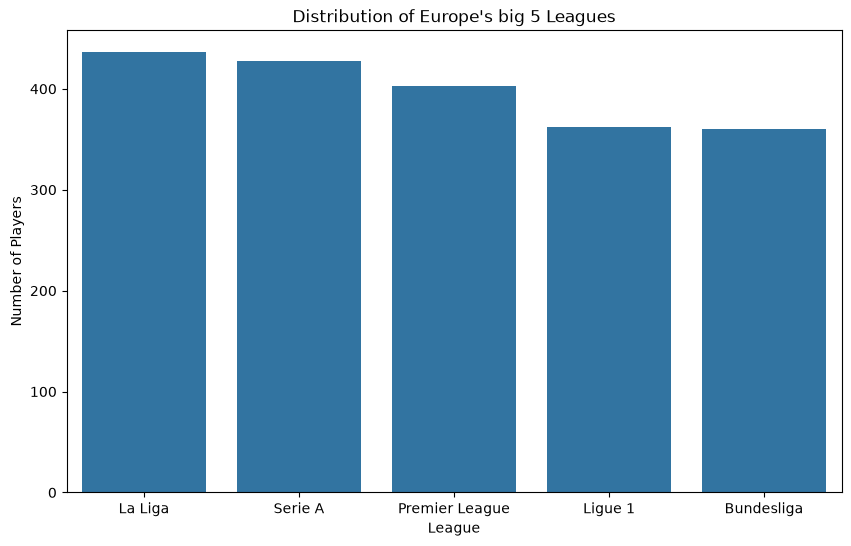

In [10]:
# Visualizing the distribution of leagues
plt.figure(figsize=(10,6))
sns.barplot(x=df['Comp'].value_counts().index, y=df['Comp'].value_counts().values)
plt.xlabel('League')
plt.ylabel('Number of Players')
plt.title("Distribution of Europe's big 5 Leagues")
plt.show()

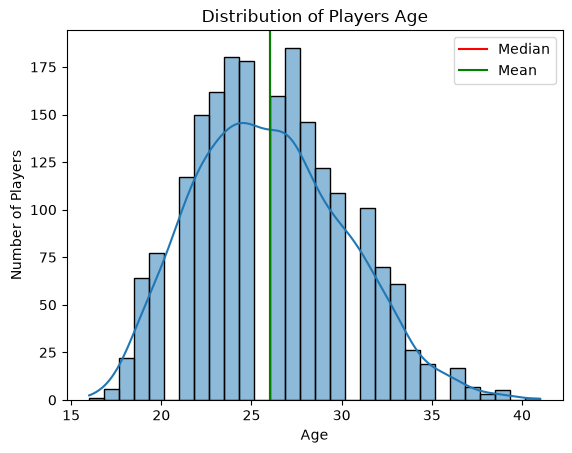

In [11]:
# Histogram with a KDE curve
plt.figure()

sns.histplot(df['Age'], bins=30, kde=True)

# Mean and median lines
plt.axvline(df['Age'].median(), color='r', label='Median')
plt.axvline(df['Age'].mean(), color='g', label='Mean')

plt.xlabel('Age')
plt.ylabel('Number of Players')
plt.title('Distribution of Players Age')
plt.legend()
plt.show()

# ------ ADDED KDE TO HISTOGRAM

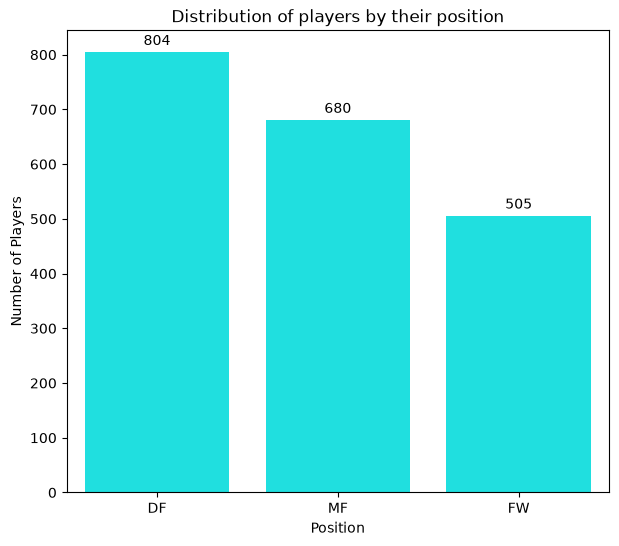

In [12]:
# players by their positions
plt.figure(figsize=(7,6))
sns.barplot(x=df['Position'].value_counts().index, y=df['Position'].value_counts().values, color="cyan")
plt.xlabel('Position')
plt.ylabel('Number of Players')
plt.title("Distribution of players by their position")

for container in plt.gca().containers:
    plt.gca().bar_label(container, padding=3)
plt.show()

In [13]:
df['Values'].describe()

count    1.989000e+03
mean     1.419932e+07
std      1.912377e+07
min      1.500000e+05
25%      3.000000e+06
50%      8.000000e+06
75%      1.700000e+07
max      2.000000e+08
Name: Values, dtype: float64

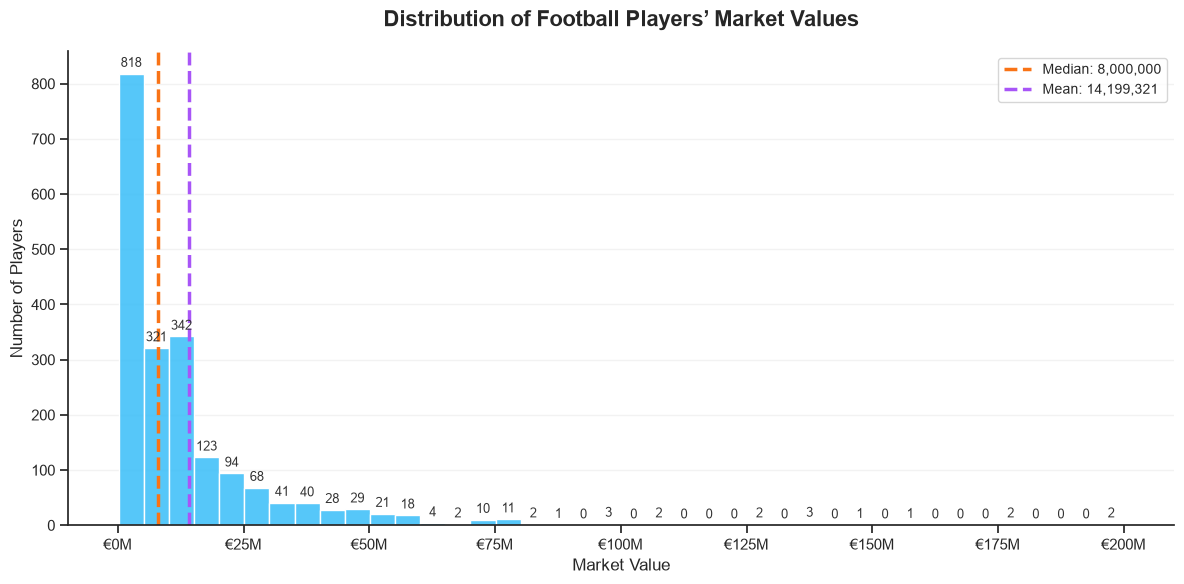

In [14]:
# imp : distribution of players market value

# this code creates a histogram showing the distribution of football players market values, with mean and median lines,
# value labels and formatting


# from here
from matplotlib.ticker import FuncFormatter

# sns - seaborn 
sns.set_theme(style="ticks", context="notebook")

fig, ax = plt.subplots(figsize=(12, 6))
# till here - func formatter helps us customize how numbers appear on the graph
#             sns.set_theme() - sets seaborn's visual style
#             plt.subplots() - creates a figure measuring 12 x 6 inches.
#             fg represents the entite figure and ax represents the actual plotting area where the graph is drawn.
#             ax gives us control over a specific graph, while plt provides general plotting functions.

sns.histplot(
    data=df,
    x='Values',
    bins=40,                # divides the market-value range into 40 intervals
    color='#38BDF8',
    edgecolor='white',
    alpha=0.85,             # used to control the transparency of bars
    ax=ax                   # draws the histogram on the plotting area created earlier.
)

median = df['Values'].median()
mean = df['Values'].mean()

ax.axvline(                                            #.axvline -> draws a virtual line at a specified x-coordinate.
    median, color='#F97316', linestyle='--',
    linewidth=2.5, label=f'Median: {median:,.0f}'
)

ax.axvline(
    mean, color='#A855F7', linestyle='--',
    linewidth=2.5, label=f'Mean: {mean:,.0f}'
)

ax.set_title(
    'Distribution of Football Players’ Market Values',
    fontsize=16, fontweight='bold', pad=18
)
ax.set_xlabel('Market Value', fontsize=12)
ax.set_ylabel('Number of Players', fontsize=12)

ax.bar_label(
    ax.containers[0], 
    fmt='%g',          
    padding=3,         
    fontsize=9,        
    color='#333'
)

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'€{x/1e6:.0f}M')      # changes how the numbers appear on the horizontal axis without changing the underlying data.
)
# ------ FLAGGED: not fully understood


ax.legend(frameon=True, fontsize=10)
ax.grid(axis='y', alpha=0.25)
ax.grid(axis='x', visible=False)
sns.despine()
plt.tight_layout()
plt.show()

In [15]:
# The number of players in the dataframe
# print("Number of unique players: ", df['Player'].nunique)
df['Player'].nunique()

1988

Top 10 players with the highest market value

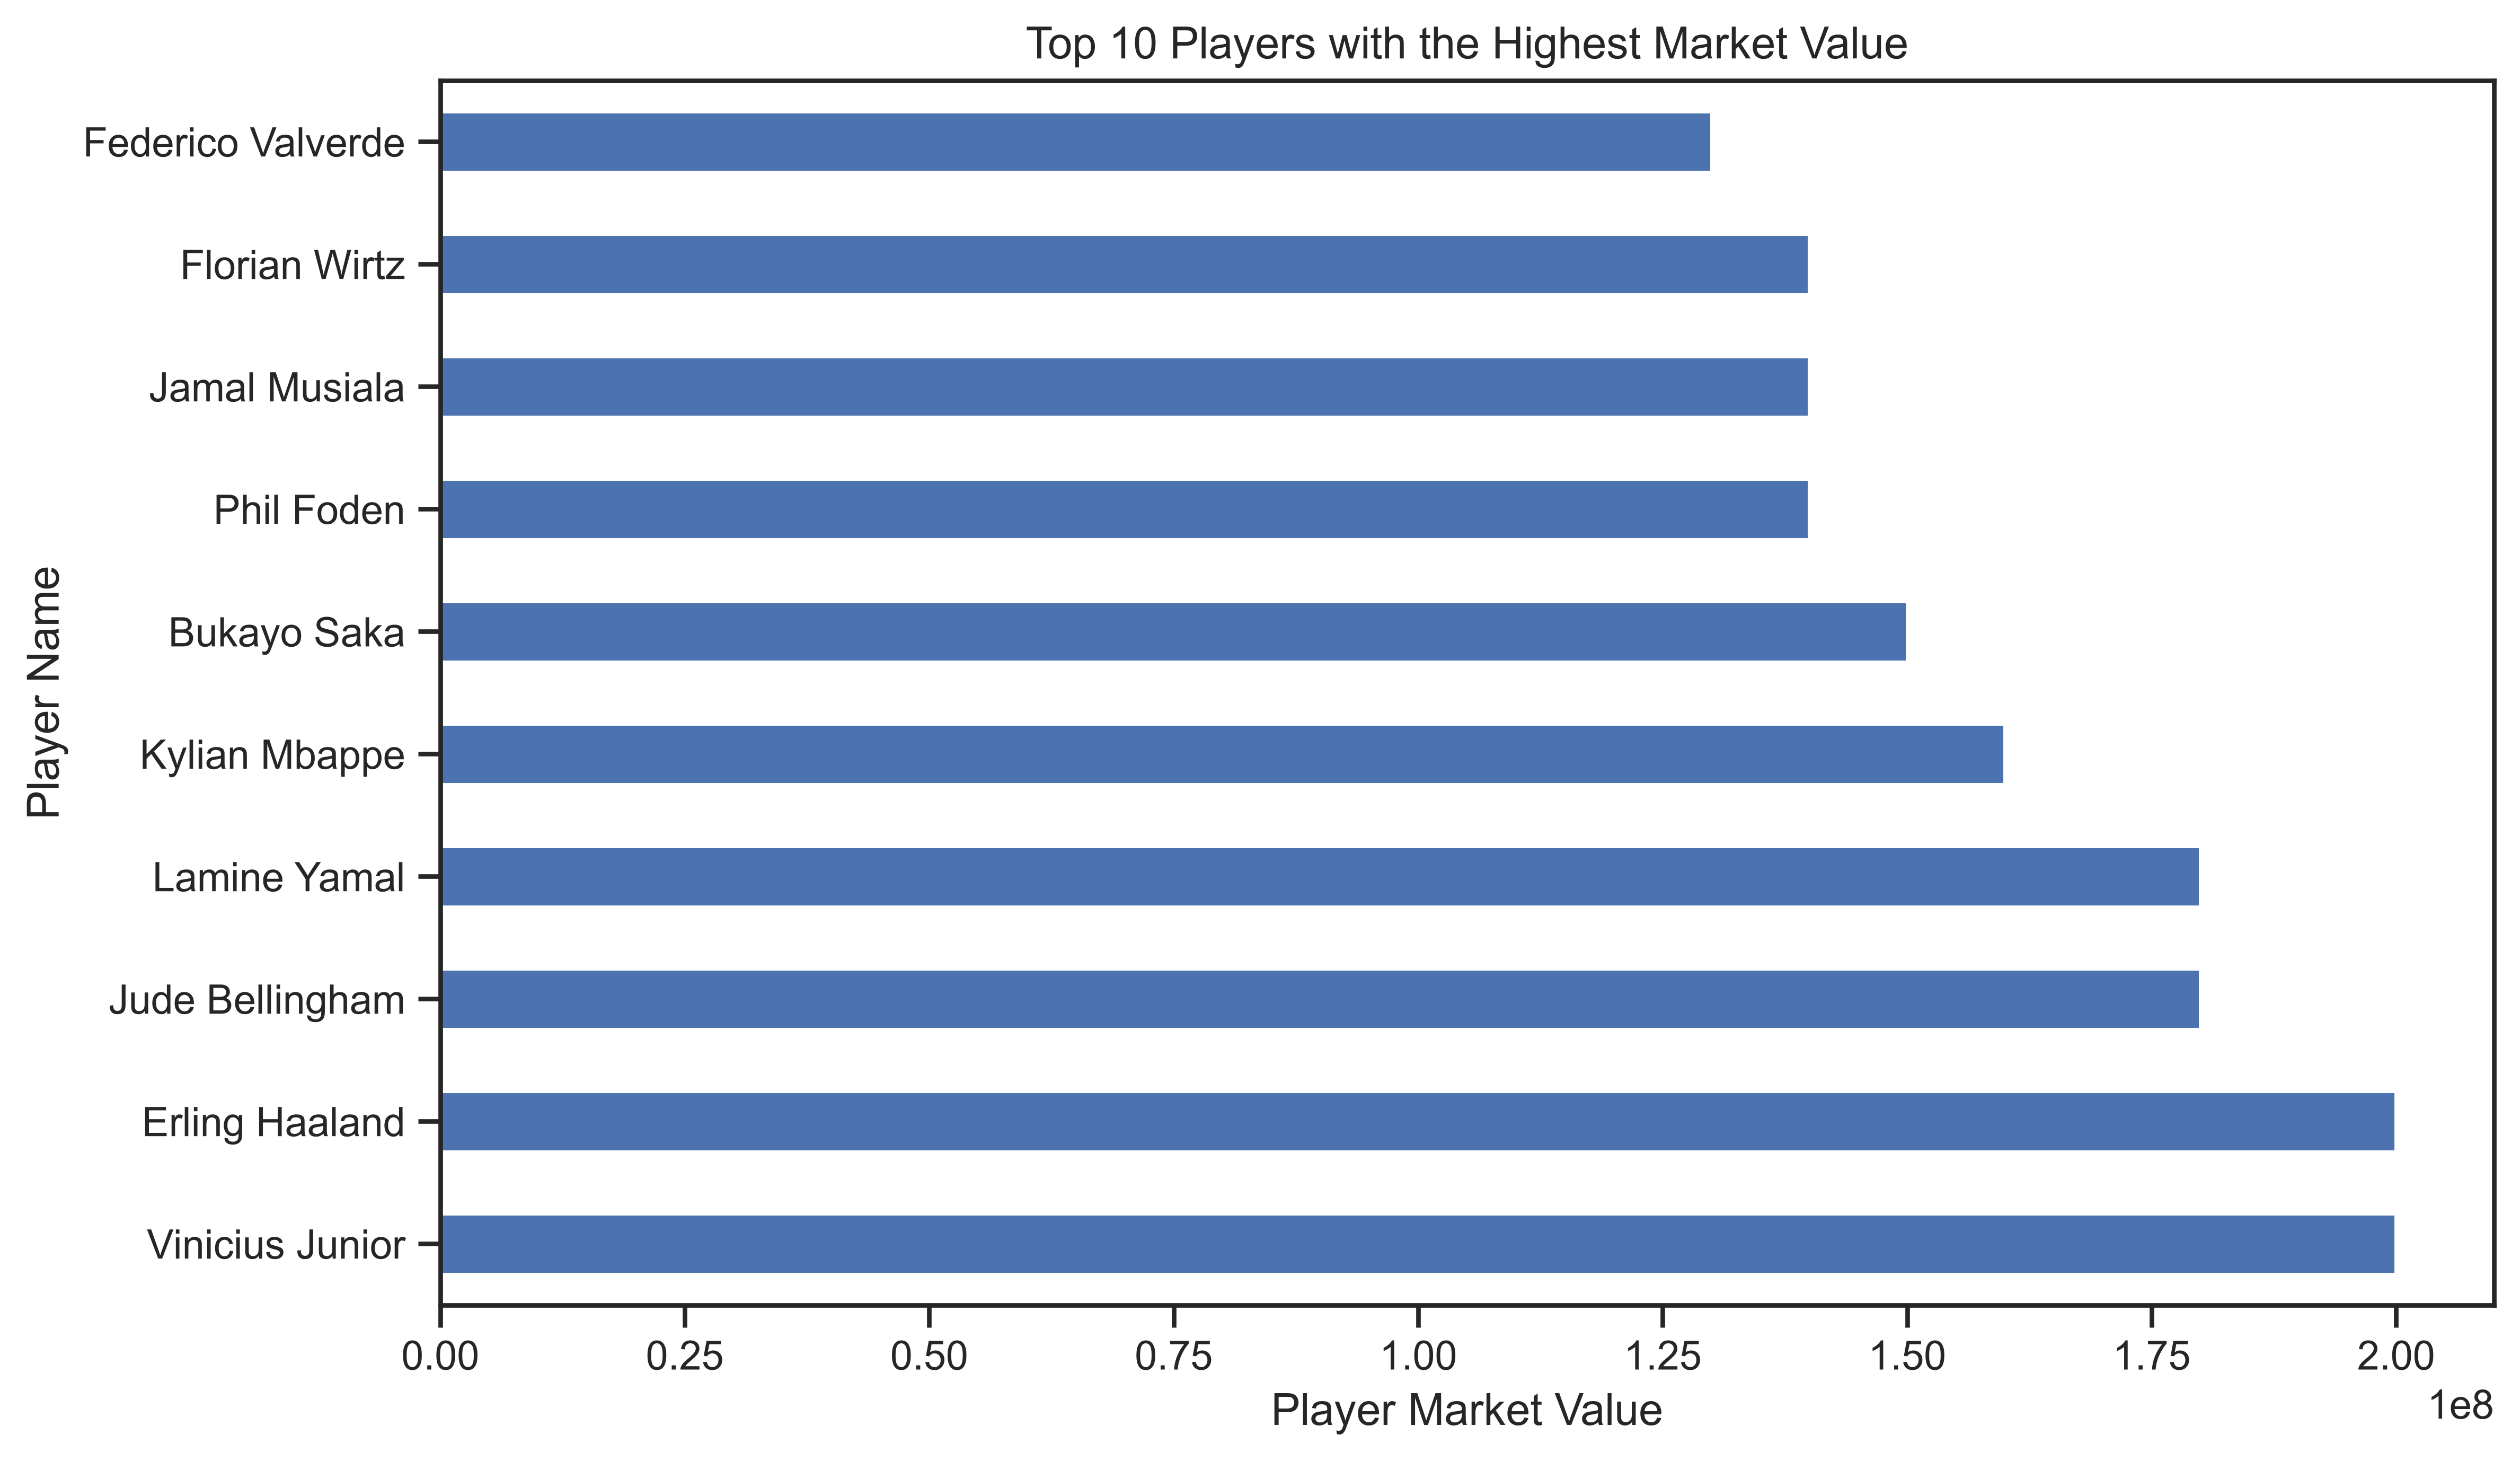

In [16]:
plt.figure(dpi=500, edgecolor='#333', figsize=(10, 6))
df.groupby('Player')['Values'].mean().sort_values(ascending=False).head(10).plot(kind='barh')

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'€{x/1e6:.0f}M')
)

plt.xlabel('Player Market Value')
plt.ylabel('Player Name')
plt.title('Top 10 Players with the Highest Market Value')   
plt.show()

In [17]:
# # players with lowest market value now
# plt.figure(edgecolor='#333', figsize=(10, 6))
# df.groupby('Player')['Values'].mean().sort_values(ascending=False).tail(10).plot(kind='barh')

# ax.xaxis.set_major_formatter(
#     FuncFormatter(lambda x, _: f'€{x/1e6:.0f}M')
# )

# plt.xlabel('Player Market Value')
# plt.ylabel('Player Name')
# plt.title('Top 10 Players with the Highest Market Value')   
# plt.show()



# ------ NOT SURE IF I WANNA KEEP THIS ONE

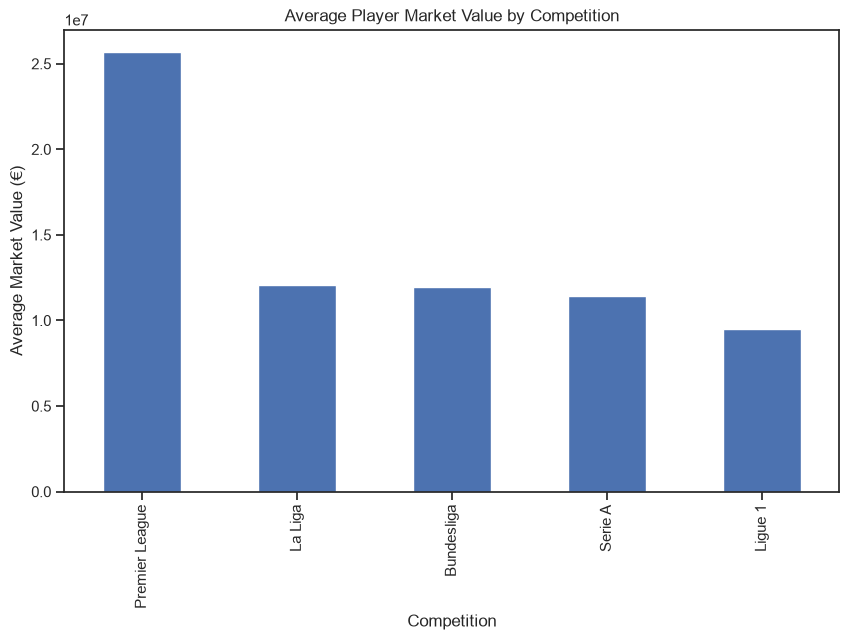

In [18]:
# pie chart lowkey not good to compare stuff like this, stick with bar chart. 

df.groupby('Comp')['Values'].mean().sort_values(
    ascending=False
).plot(kind='bar', figsize=(10, 6))

plt.title('Average Player Market Value by Competition')
plt.xlabel('Competition')
plt.ylabel('Average Market Value (€)')
plt.show()

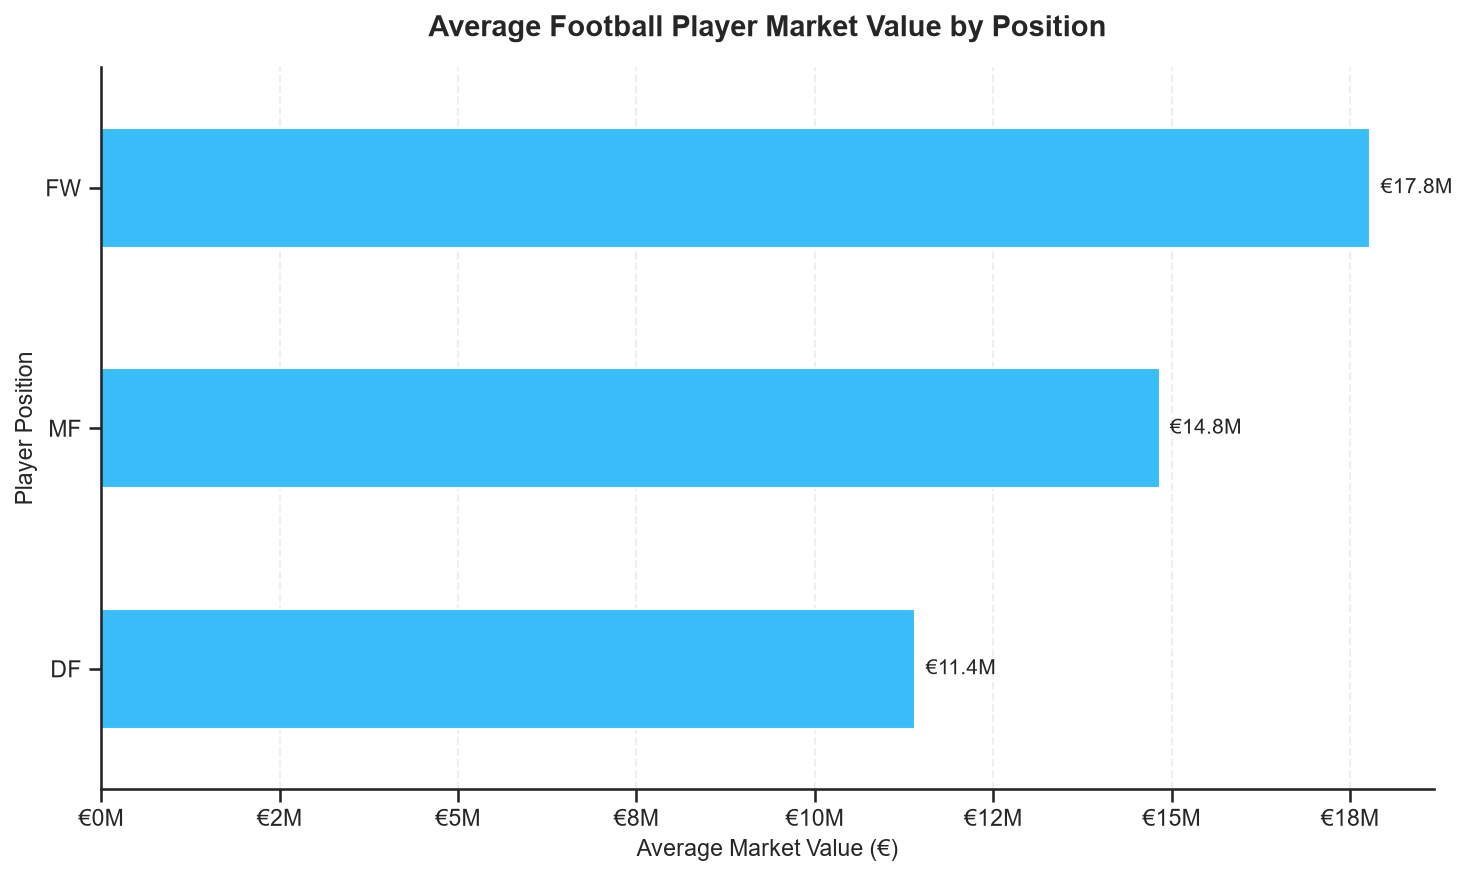

In [19]:
# Visualizing Average Player Market Value by Position
plt.figure(figsize=(10, 6), dpi=150)

ax = df.groupby('Position')['Values'].mean().sort_values().plot(
    kind='barh',
    color='#38BDF8',
    edgecolor='white',
    width=0.5
)

ax.bar_label(
    ax.containers[0],
    labels=[f'€{v/1e6:.1f}M' for v in df.groupby('Position')['Values'].mean().sort_values()],
    padding=5,
    fontsize=10
)

ax.set_xlabel('Average Market Value (€)', fontsize=11)
ax.set_ylabel('Player Position', fontsize=11)
ax.set_title(
    'Average Football Player Market Value by Position',
    fontsize=14,
    fontweight='bold',
    pad=15
)

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'€{x/1e6:.0f}M')
)

ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
sns.despine()
plt.tight_layout()
plt.show()


The horizontal barchart above shows that Attackers have the highest average Market Value among other positions which is around 17.8 million. This makes sense as these are the goal scoring players who can actually turn a game in favor of the team and gets the spotlight as well. This is followed by Midfielders and Defenders with around 14.8 million and 11.4 million respectively. We will now take a look at each Player positions with respect to their Market Values.

In [20]:
# Starting by creating their seperate dataframe

defender_df = df[df['Position'] == 'DF']
midfielder_df = df[df['Position'] == 'MF']
attacker_df = df[df['Position'] == 'FW']


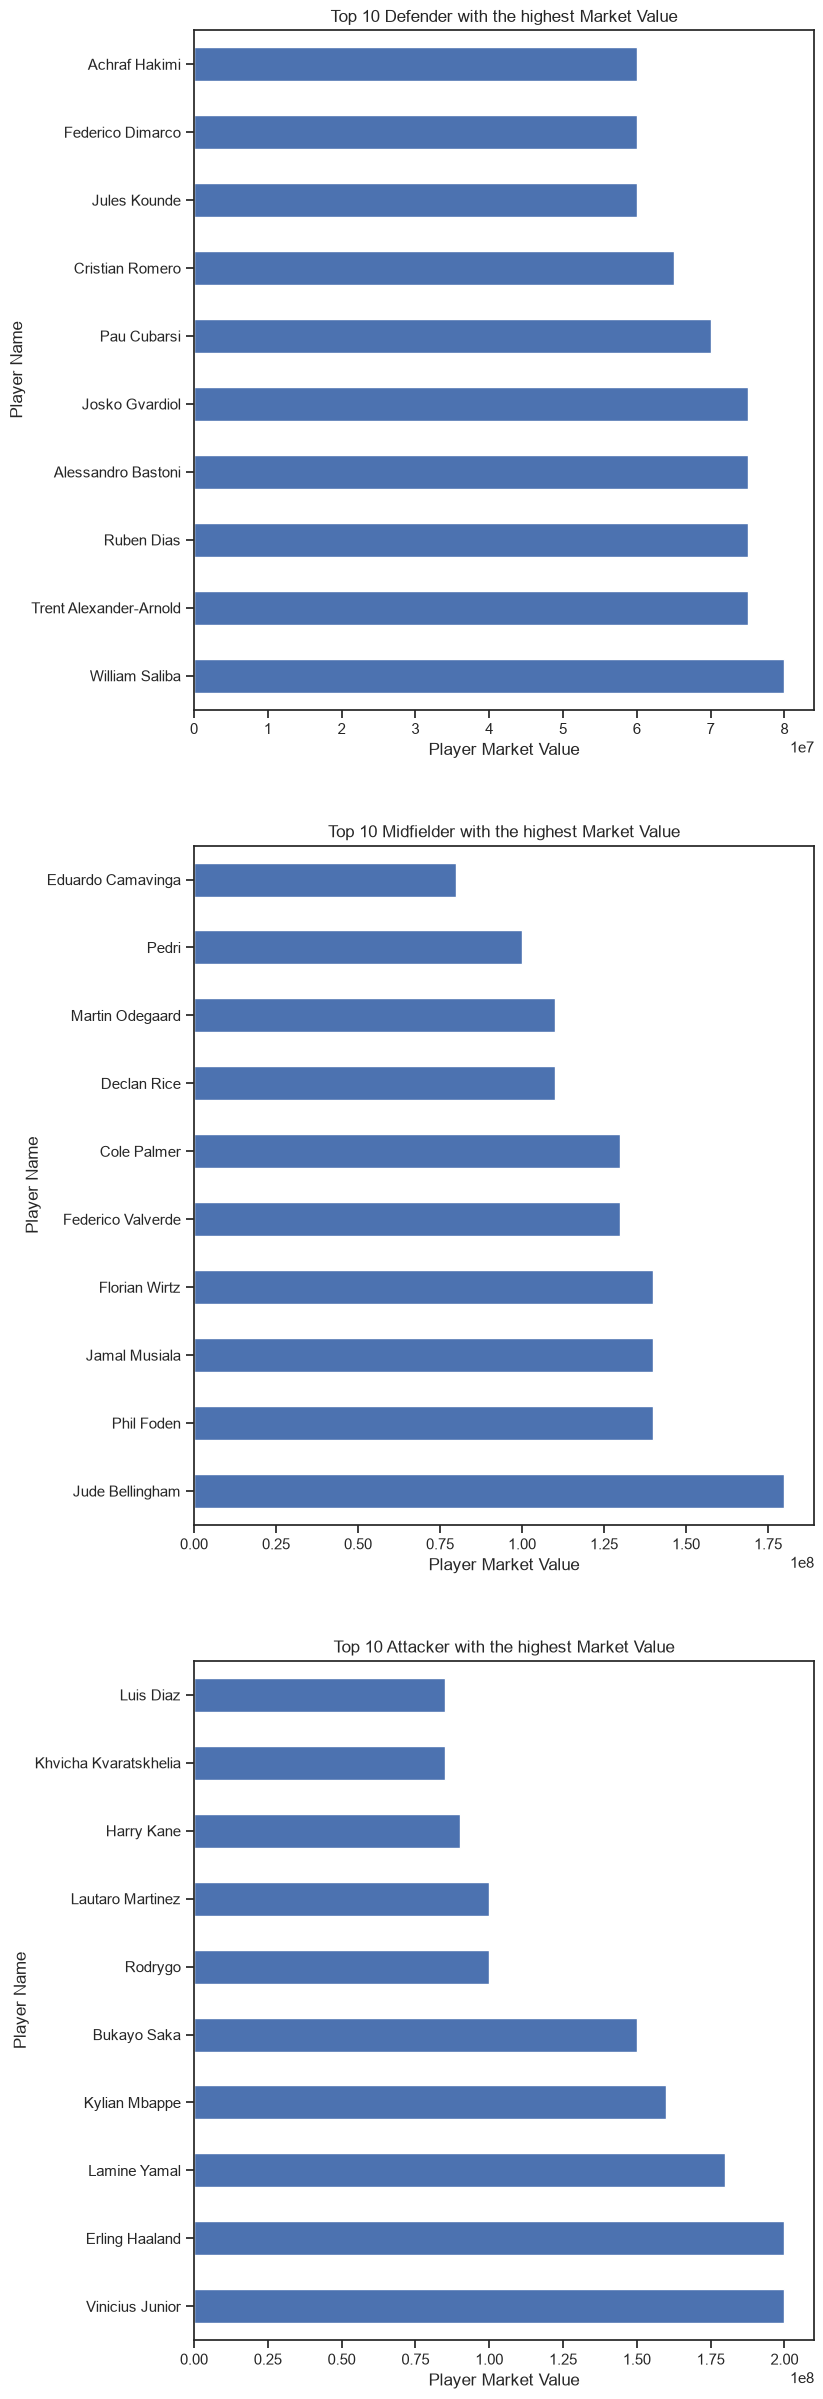

In [21]:
# Visualizing Player positions with respect to their Market Values
plt.subplots(3, 1, figsize=(8, 30))

# Visualizing top 10 Defender with highest Market Values
plt.subplot(3, 1, 1)
defender_df.groupby(['Player'])['Values'].mean().sort_values(ascending=False).head(10).plot(kind='barh')   
plt.xlabel('Player Market Value')
plt.ylabel('Player Name')
plt.title('Top 10 Defender with the highest Market Value')

# Visualizing top 10 Midfielder with highest Market Values
plt.subplot(3, 1, 2)
midfielder_df.groupby(['Player'])['Values'].mean().sort_values(ascending=False).head(10).plot(kind='barh')   
plt.xlabel('Player Market Value')
plt.ylabel('Player Name')
plt.title('Top 10 Midfielder with the highest Market Value')

# Visualizing top 10 Attacker with highest Market Values
plt.subplot(3, 1, 3)
attacker_df.groupby(['Player'])['Values'].mean().sort_values(ascending=False).head(10).plot(kind='barh')   
plt.xlabel('Player Market Value')
plt.ylabel('Player Name')
plt.title('Top 10 Attacker with the highest Market Value')

plt.show()

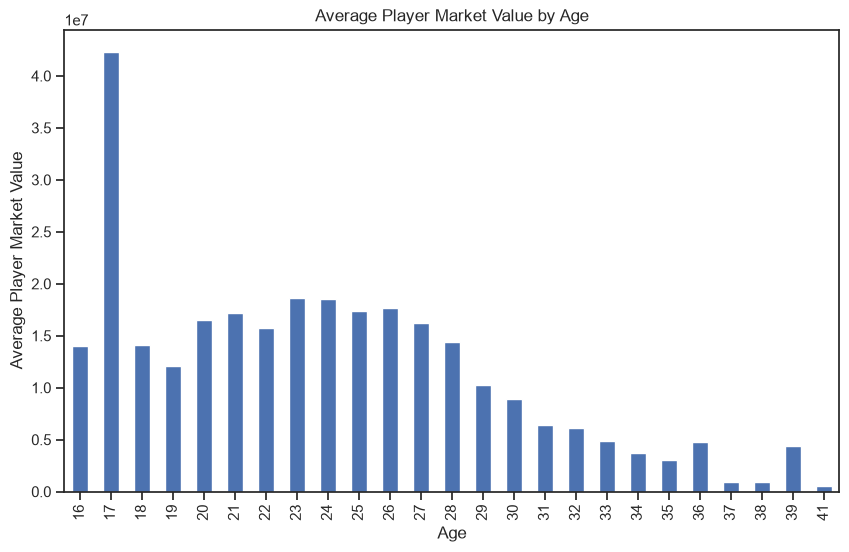

In [22]:
# Visualizing the Average Player Market Value by their Age
plt.figure(figsize=(10, 6))
df.groupby(['Age'])['Values'].mean().plot(kind='bar')
plt.xlabel('Age')
plt.ylabel('Average Player Market Value')
plt.title('Average Player Market Value by Age')
plt.show()

The chart showing the average market value of football players by age. The highest market value is at age 17, after which it generally declines with increasing age.

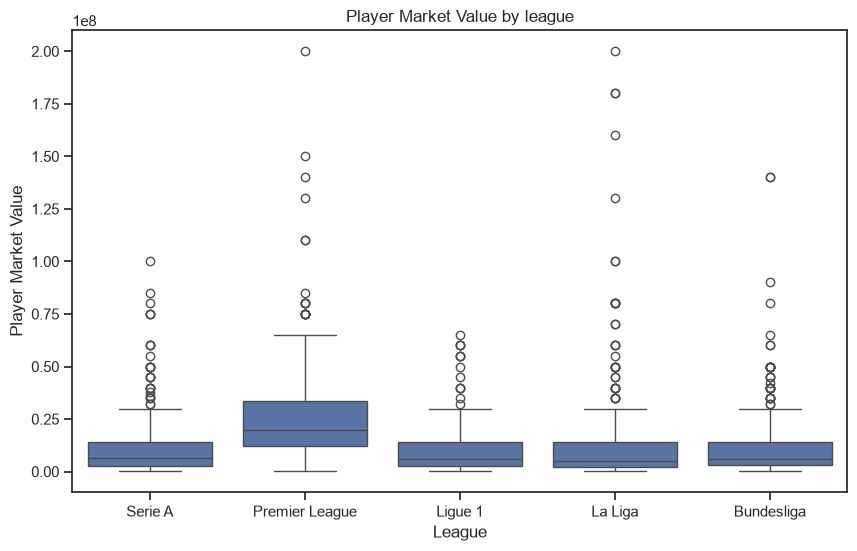

In [23]:
# relationship between league and players market value
# use a boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(x="Comp", y="Values", data=df)
plt.xlabel('League')
plt.ylabel('Player Market Value')
plt.title('Player Market Value by league')
plt.show()

In [24]:
df['Team'].nunique()

team_val = df.groupby(['Team'])['Values'].sum().sort_values(ascending=False)

team_val_df = pd.DataFrame({'Team': team_val.index, 'Total Value': team_val.values})
team_val_df.head(20)

,Team,Total Value
0,real madrid,1.177000e+09
1,manchester city,9.820000e+08
2,barcelona,9.785000e+08
3,arsenal,9.730000e+08
4,chelsea,8.760000e+08
5,bayern munich,8.140000e+08
6,liverpool,7.880000e+08
7,tottenham,7.400000e+08
8,paris s-g,7.325000e+08
9,manchester utd,7.175000e+08


Real Madrid have the highest aggregate players market value in World followed by Manchester City and Barcelona.

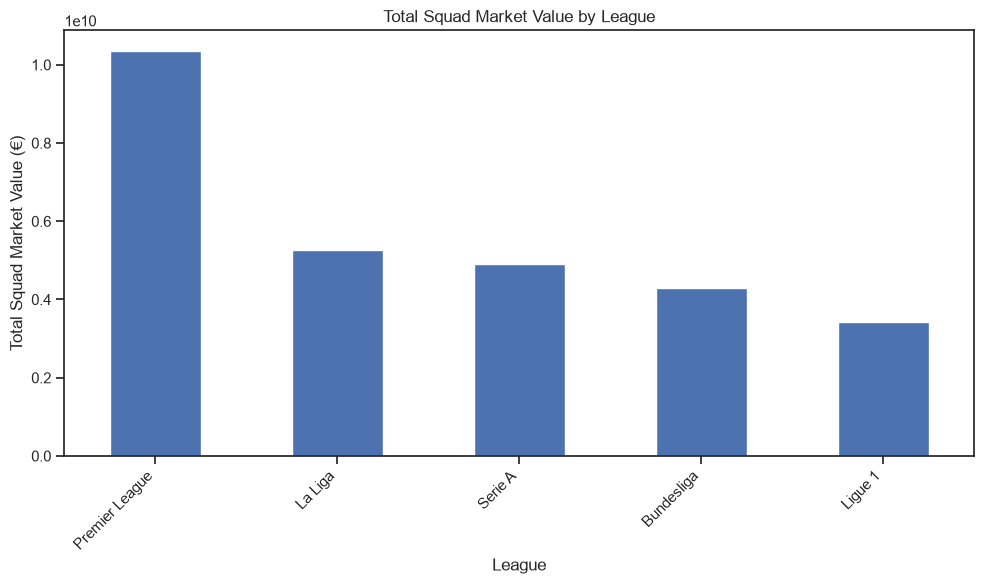

In [25]:
# Calculate total market value of players in each league
league_total_value = (
    df.groupby('Comp')['Values']
    .sum()
    .sort_values(ascending=False)
)

# Visualize the results
league_total_value.plot(kind='bar', figsize=(10, 6))

plt.xlabel('League')
plt.ylabel('Total Squad Market Value (€)')
plt.title('Total Squad Market Value by League')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Premier League has a higher squad value compared to other leagues

# Data Building

In [26]:
# create copy of dataset
data = df.copy();
data

,Player,Position,Team,Comp,Age,MP,Min,Goals,Ast,G+A,...,Clearances,Errors,Dribbles Successful,Dribble Distance,Mistakes,Ball Recoveries,Air Duels Won%,Values,Value Team,Team Value Group
0,Antonio Raimondo,FW,venezia,Serie A,20,9,94,0,0,0,...,0,1,0,48,5,4,14.3,14000000.0,72500000.0,1
1,Anthony Gordon,FW,newcastle utd,Premier League,23,22,1766,6,5,11,...,9,2,33,2619,22,82,45.5,60000000.0,500500000.0,3
2,Frank Magri,FW,toulouse,Ligue 1,25,17,413,0,0,0,...,5,0,2,192,12,5,45.9,2500000.0,76100000.0,1
3,Timothy Weah,FW,juventus,Serie A,24,14,749,5,1,6,...,6,0,8,564,7,21,36.8,17000000.0,545000000.0,3
4,Matthijs de Ligt,DF,manchester utd,Premier League,25,21,1540,1,0,1,...,52,0,1,4341,3,49,68.4,45000000.0,672500000.0,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1984,Igor Zubeldia,DF,real sociedad,La Liga,27,18,1565,0,0,0,...,64,2,1,5467,6,57,45.9,22000000.0,363500000.0,3
1985,Thibault De Smet,DF,reims,Ligue 1,26,5,192,0,0,0,...,12,0,0,575,2,6,50.0,14000000.0,110300000.0,2
1986,Ilaix Moriba,MF,celta vigo,La Liga,22,18,1080,0,1,1,...,17,0,9,2154,26,58,52.0,4000000.0,119600000.0,2
1987,Gerard Moreno,FW,villarreal,La Liga,32,11,539,3,1,4,...,5,0,9,748,11,17,80.0,5000000.0,175300000.0,2


In [27]:
data.columns

Index(['Player', 'Position', 'Team', 'Comp', 'Age', 'MP', 'Min', 'Goals',
       'Ast', 'G+A', 'xG', 'xA', 'SoT%', 'npxG/Sh', 'G-xG', 'Pass Cmp%',
       'Through Balls', 'Switch Passes', 'Crosses', 'Shot Creating Actions',
       'Def Action to Shot', 'Tackles', 'Shots Blocked', 'Interceptions',
       'Clearances', 'Errors', 'Dribbles Successful', 'Dribble Distance',
       'Mistakes', 'Ball Recoveries', 'Air Duels Won%', 'Values', 'Value Team',
       'Team Value Group'],
      dtype='str')

In [28]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1989 entries, 0 to 1988
Data columns (total 34 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   Player                 1989 non-null   str     
 1   Position               1989 non-null   object  
 2   Team                   1989 non-null   str     
 3   Comp                   1989 non-null   str     
 4   Age                    1989 non-null   int64   
 5   MP                     1989 non-null   int64   
 6   Min                    1989 non-null   int64   
 7   Goals                  1989 non-null   int64   
 8   Ast                    1989 non-null   int64   
 9   G+A                    1989 non-null   int64   
 10  xG                     1989 non-null   float64 
 11  xA                     1989 non-null   float64 
 12  SoT%                   1989 non-null   float64 
 13  npxG/Sh                1989 non-null   float64 
 14  G-xG                   1989 non-null   float64 
 15

It converts categorical values like DF, MF, and FW into numerical columns that machine learning models can use (the code below).

In [29]:
# dummy positions
dummy_pos_grp = pd.get_dummies(data['Position'])

# adding to data frame
data = pd.concat([data, dummy_pos_grp], axis=1)

data.drop('Position', axis=1, inplace=True)

In [30]:
data.head(10)

,Player,Team,Comp,Age,MP,Min,Goals,Ast,G+A,xG,...,Dribble Distance,Mistakes,Ball Recoveries,Air Duels Won%,Values,Value Team,Team Value Group,DF,FW,MF
0,Antonio Raimondo,venezia,Serie A,20,9,94,0,0,0,0.3,...,48,5,4,14.3,14000000.0,72500000.0,1,False,True,False
1,Anthony Gordon,newcastle utd,Premier League,23,22,1766,6,5,11,7.3,...,2619,22,82,45.5,60000000.0,500500000.0,3,False,True,False
2,Frank Magri,toulouse,Ligue 1,25,17,413,0,0,0,1.0,...,192,12,5,45.9,2500000.0,76100000.0,1,False,True,False
3,Timothy Weah,juventus,Serie A,24,14,749,5,1,6,2.9,...,564,7,21,36.8,17000000.0,545000000.0,3,False,True,False
4,Matthijs de Ligt,manchester utd,Premier League,25,21,1540,1,0,1,1.8,...,4341,3,49,68.4,45000000.0,672500000.0,4,True,False,False
5,Keinan Davis,udinese,Serie A,26,14,688,2,1,3,1.5,...,338,24,27,53.8,14000000.0,155500000.0,2,False,True,False
6,Conor Chaplin,ipswich town,Premier League,27,15,614,1,1,2,1.2,...,699,9,23,11.1,14000000.0,217400000.0,2,False,False,True
7,Brian Olivan,espanyol,La Liga,30,17,1017,0,1,1,0.4,...,2788,10,28,23.1,2000000.0,70400000.0,1,True,False,False
8,Ferran Torres,barcelona,La Liga,24,15,617,4,2,6,3.6,...,453,13,14,20.0,28000000.0,950500000.0,4,False,True,False
9,Karol Linetty,torino,Serie A,29,19,1198,1,0,1,0.6,...,1686,13,54,35.3,3500000.0,144300000.0,2,False,False,True


In [31]:
# removing the unneeded columns

# player, temp, comp are not identifers they are strings and hence wont contribute in regression model
data.drop(['Player', 'Team', 'Comp'], axis=1, inplace=True)
data.head()

,Age,MP,Min,Goals,Ast,G+A,xG,xA,SoT%,npxG/Sh,...,Dribble Distance,Mistakes,Ball Recoveries,Air Duels Won%,Values,Value Team,Team Value Group,DF,FW,MF
0,20,9,94,0,0,0,0.3,0.2,100.0,0.32,...,48,5,4,14.3,14000000.0,72500000.0,1,False,True,False
1,23,22,1766,6,5,11,7.3,4.4,31.9,0.12,...,2619,22,82,45.5,60000000.0,500500000.0,3,False,True,False
2,25,17,413,0,0,0,1.0,0.2,21.4,0.07,...,192,12,5,45.9,2500000.0,76100000.0,1,False,True,False
3,24,14,749,5,1,6,2.9,0.6,58.3,0.24,...,564,7,21,36.8,17000000.0,545000000.0,3,False,True,False
4,25,21,1540,1,0,1,1.8,0.2,46.2,0.14,...,4341,3,49,68.4,45000000.0,672500000.0,4,True,False,False


All the categorical columns have been converted to numerical values and the dataset is ready for modeling. I will take a look at all the columns.

In [32]:
data.columns

Index(['Age', 'MP', 'Min', 'Goals', 'Ast', 'G+A', 'xG', 'xA', 'SoT%',
       'npxG/Sh', 'G-xG', 'Pass Cmp%', 'Through Balls', 'Switch Passes',
       'Crosses', 'Shot Creating Actions', 'Def Action to Shot', 'Tackles',
       'Shots Blocked', 'Interceptions', 'Clearances', 'Errors',
       'Dribbles Successful', 'Dribble Distance', 'Mistakes',
       'Ball Recoveries', 'Air Duels Won%', 'Values', 'Value Team',
       'Team Value Group', 'DF', 'FW', 'MF'],
      dtype='str')

In [33]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1989 entries, 0 to 1988
Data columns (total 33 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   Age                    1989 non-null   int64   
 1   MP                     1989 non-null   int64   
 2   Min                    1989 non-null   int64   
 3   Goals                  1989 non-null   int64   
 4   Ast                    1989 non-null   int64   
 5   G+A                    1989 non-null   int64   
 6   xG                     1989 non-null   float64 
 7   xA                     1989 non-null   float64 
 8   SoT%                   1989 non-null   float64 
 9   npxG/Sh                1989 non-null   float64 
 10  G-xG                   1989 non-null   float64 
 11  Pass Cmp%              1989 non-null   float64 
 12  Through Balls          1989 non-null   int64   
 13  Switch Passes          1989 non-null   int64   
 14  Crosses                1989 non-null   int64   
 15

In [34]:
corr_X = data.corr();
corr_X

,Age,MP,Min,Goals,Ast,G+A,xG,xA,SoT%,npxG/Sh,...,Dribble Distance,Mistakes,Ball Recoveries,Air Duels Won%,Values,Value Team,Team Value Group,DF,FW,MF
Age,1.000000,0.081440,0.101098,0.002428,0.015802,0.008649,0.023799,0.044676,-0.034413,0.044536,...,0.169972,-0.096165,0.057245,0.114517,-0.197502,-0.044177,-0.046413,0.079070,-0.041770,-0.043477
MP,0.081440,1.000000,0.857184,0.392349,0.421799,0.465485,0.425301,0.507785,0.128314,0.132732,...,0.477245,0.614897,0.722274,-0.014449,0.260350,0.070317,0.080055,-0.139577,0.106914,0.046302
Min,0.101098,0.857184,1.000000,0.363704,0.407152,0.438562,0.376722,0.509085,0.071408,0.049294,...,0.696378,0.558429,0.850237,0.102202,0.298784,0.055931,0.064216,0.093503,-0.077308,-0.025801
Goals,0.002428,0.392349,0.363704,1.000000,0.472024,0.922705,0.894896,0.454593,0.302192,0.333588,...,-0.086669,0.638056,0.139128,-0.119781,0.436740,0.154346,0.152213,-0.324468,0.437224,-0.065496
Ast,0.015802,0.421799,0.407152,0.472024,1.000000,0.775397,0.484608,0.724114,0.122775,0.103031,...,0.115879,0.515367,0.339624,-0.136949,0.422912,0.206917,0.209113,-0.219516,0.211996,0.032585
G+A,0.008649,0.465485,0.438562,0.922705,0.775397,1.000000,0.852922,0.642269,0.270147,0.284002,...,-0.011408,0.682400,0.248171,-0.145754,0.497769,0.201040,0.200472,-0.328406,0.405885,-0.032665
xG,0.023799,0.425301,0.376722,0.894896,0.484608,0.852922,1.000000,0.443977,0.248526,0.411347,...,-0.112232,0.678145,0.130045,-0.117818,0.430697,0.157338,0.160607,-0.368904,0.496064,-0.073513
xA,0.044676,0.507785,0.509085,0.454593,0.724114,0.642269,0.443977,1.000000,0.137676,0.036095,...,0.239459,0.558722,0.490167,-0.154030,0.433694,0.201164,0.207571,-0.213429,0.141034,0.091401
SoT%,-0.034413,0.128314,0.071408,0.302192,0.122775,0.270147,0.248526,0.137676,1.000000,0.357511,...,-0.055871,0.183743,0.015749,-0.082110,0.109707,0.041844,0.045185,-0.149937,0.212877,-0.040208
npxG/Sh,0.044536,0.132732,0.049294,0.333588,0.103031,0.284002,0.411347,0.036095,0.357511,1.000000,...,-0.101066,0.177305,-0.055703,-0.024966,0.119137,0.102175,0.098036,-0.167729,0.307579,-0.108696


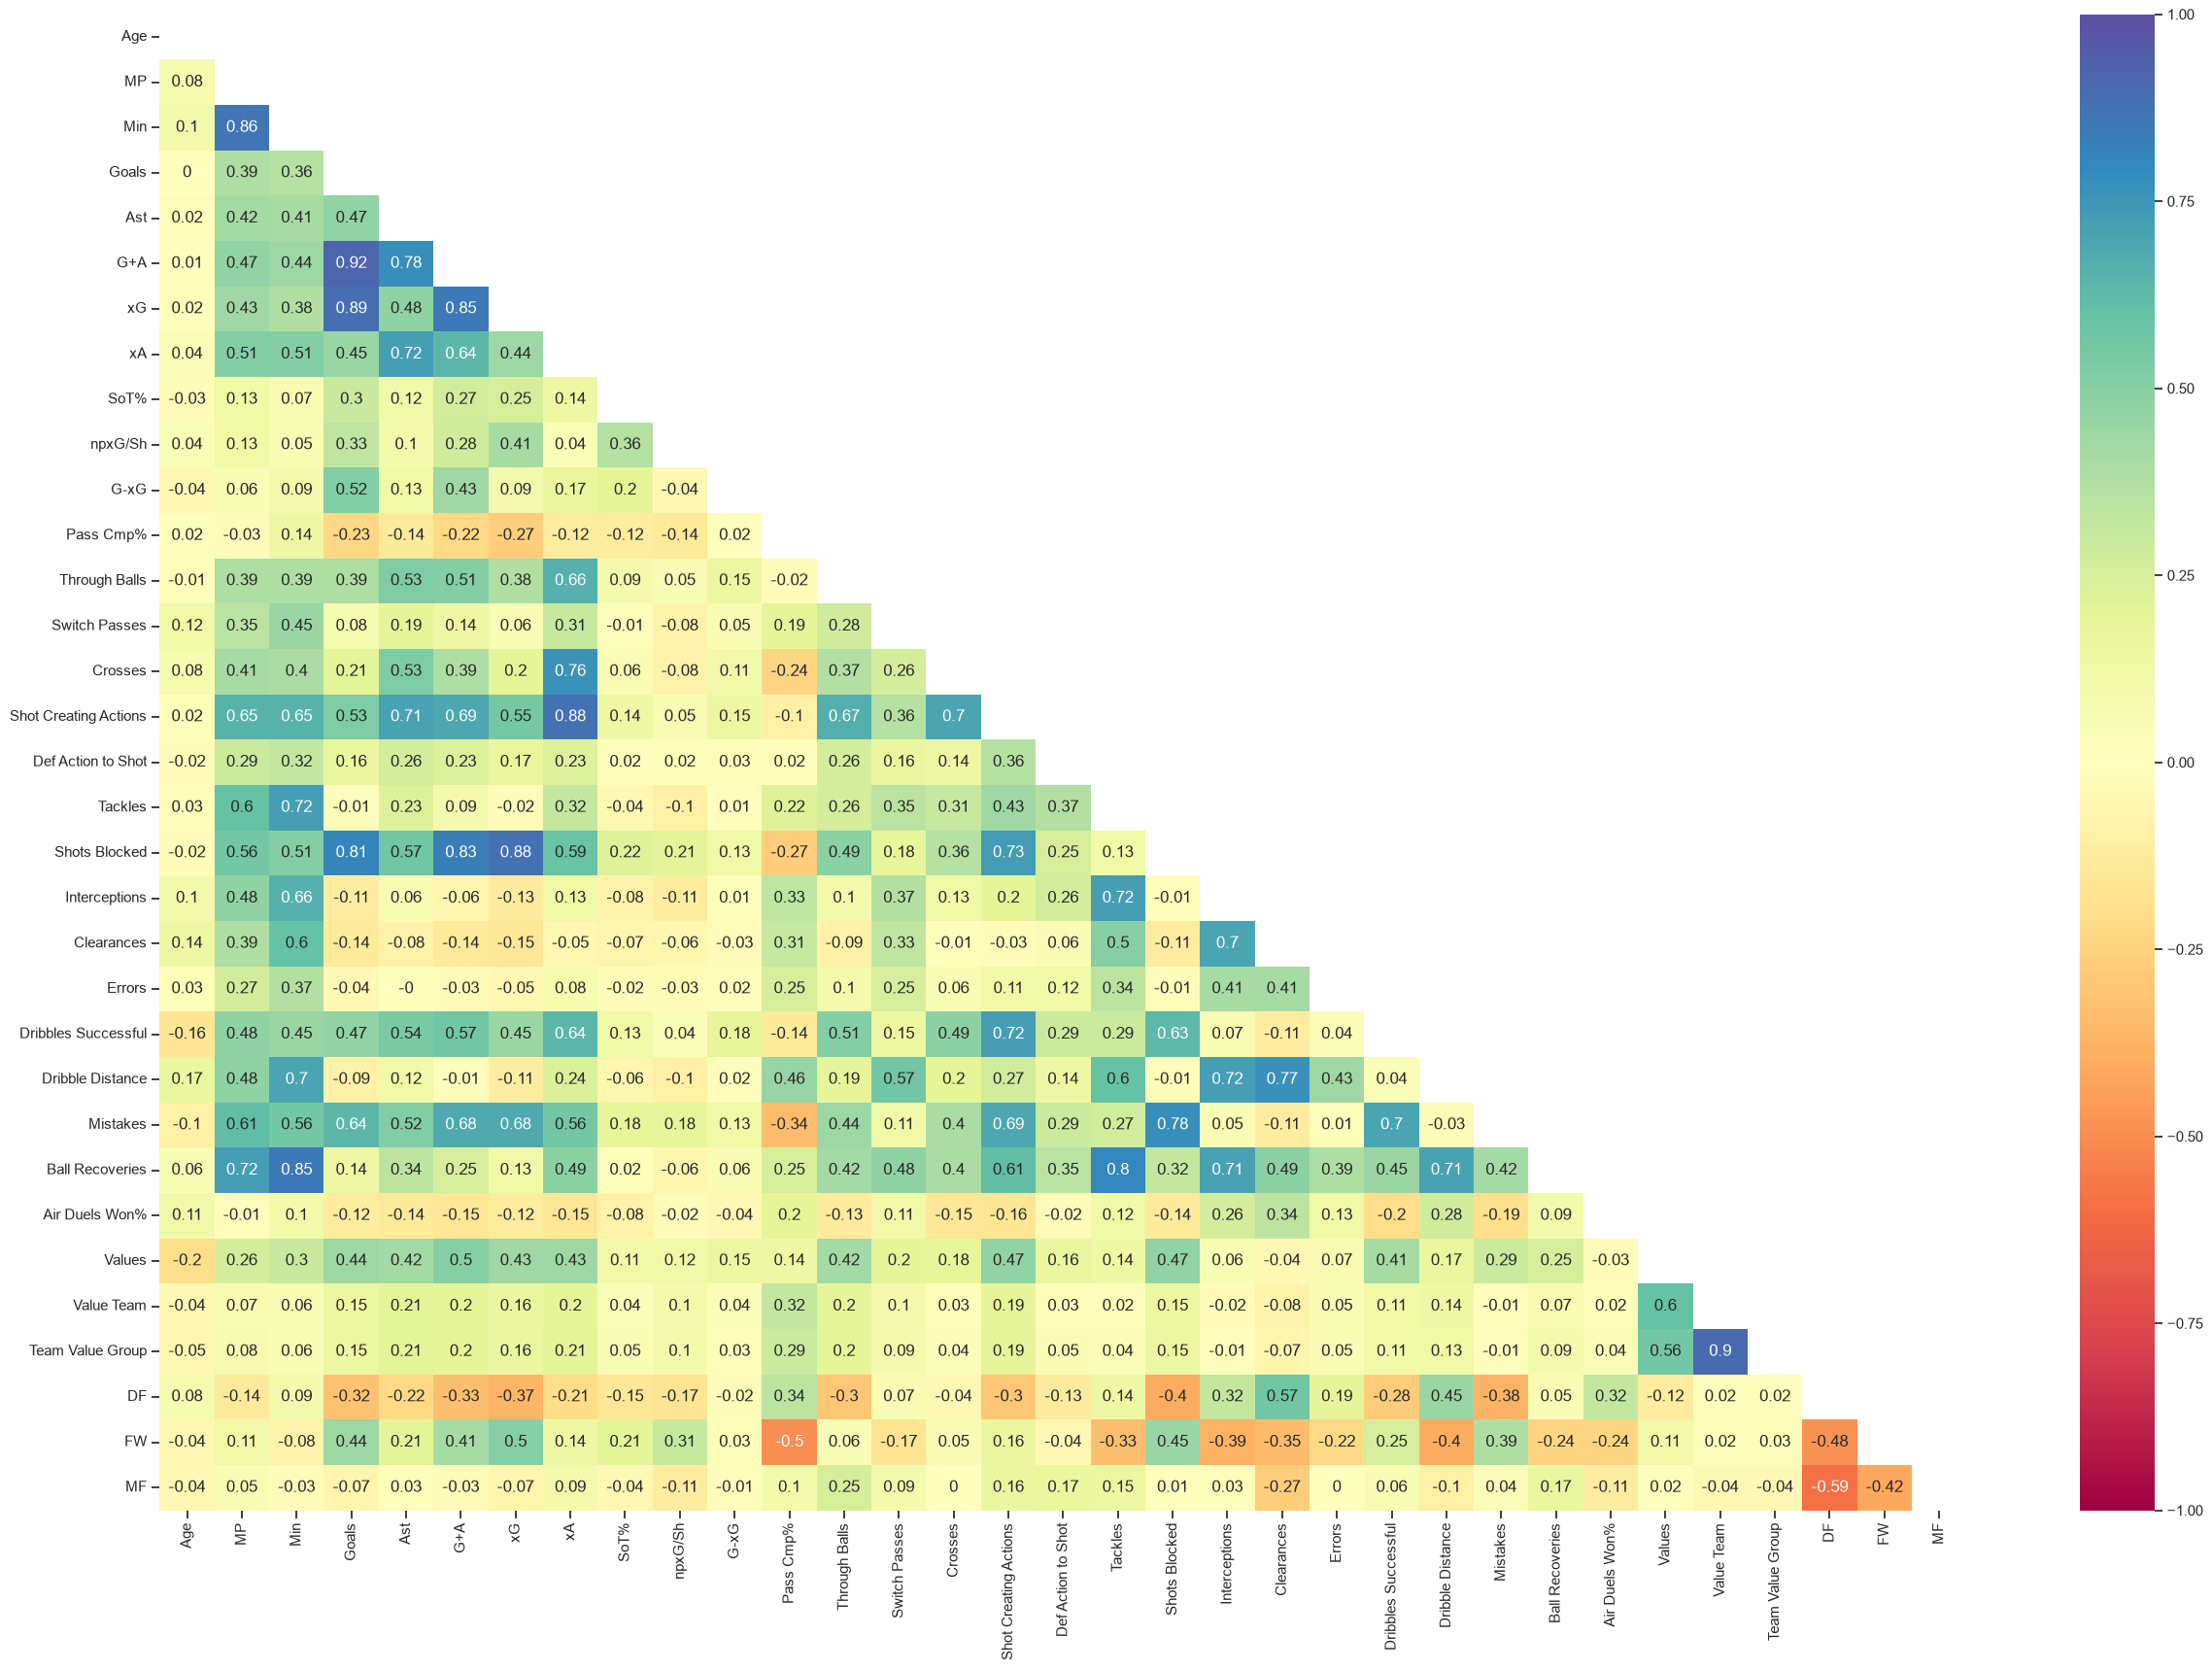

In [35]:
# Creating heatmapp
mask = np.triu(corr_X)      # uppar trinagular matrix

plt.figure(figsize=(30, 20))
sns.heatmap(corr_X.round(2), annot=True, vmax=1, vmin=-1, center=0, cmap='Spectral', mask=mask)
plt.show()

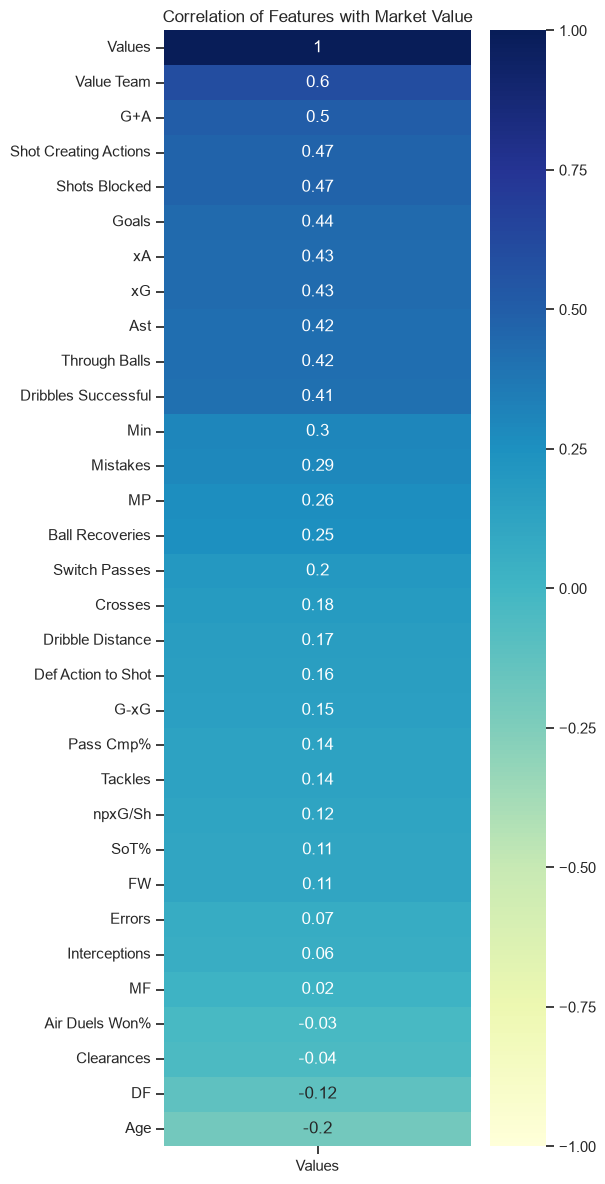

In [36]:
# correlation to the values only
corr_values = data.corr(numeric_only=True)['Values'].sort_values(ascending=False)

plt.figure(figsize=(6, 12))
sns.heatmap(
    corr_values.to_frame().round(2),
    annot=True,
    cmap='YlGnBu',
    vmin=-1,
    vmax=1,
    center=0
)
plt.title('Correlation of Features with Market Value')
plt.tight_layout()
plt.show()

In [37]:
# features and target
X = data.drop(columns=["Values"])     # we drop values from the features to prevent data leakage.
y = data["Values"]

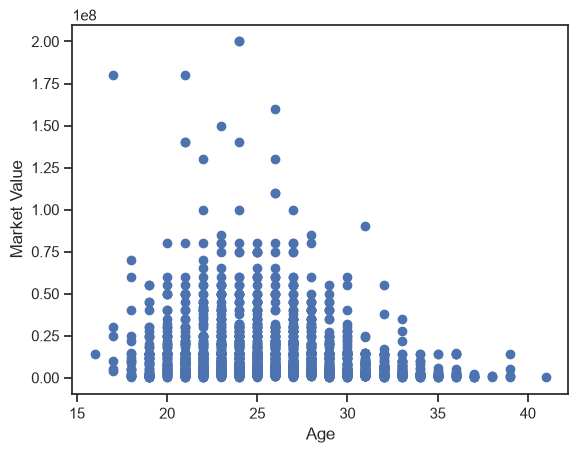

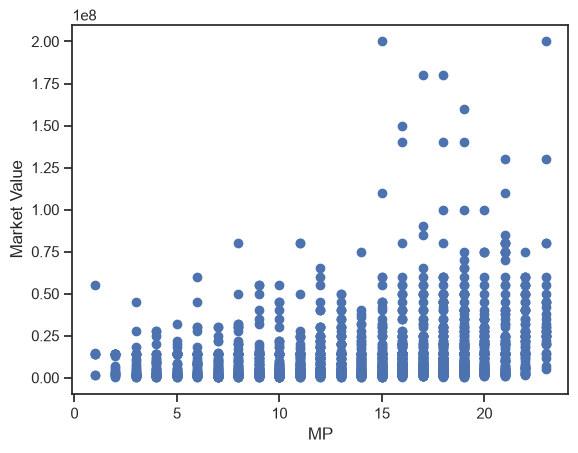

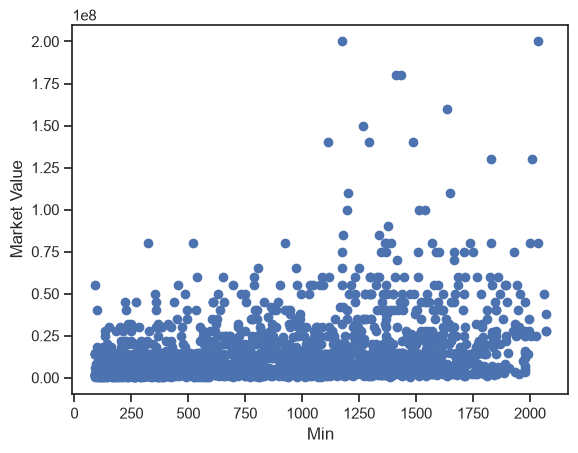

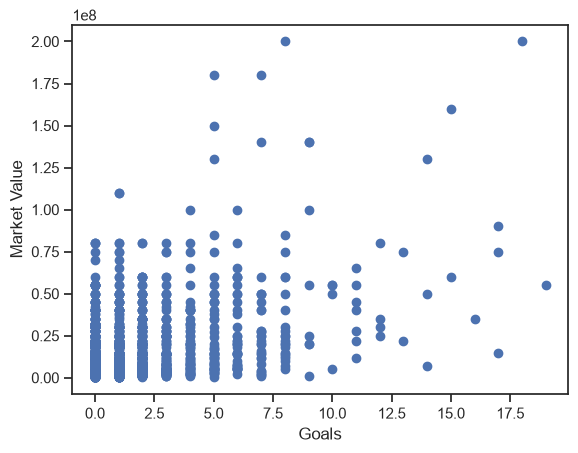

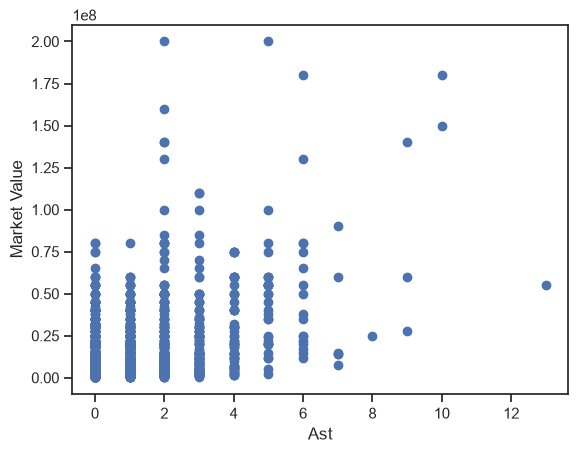

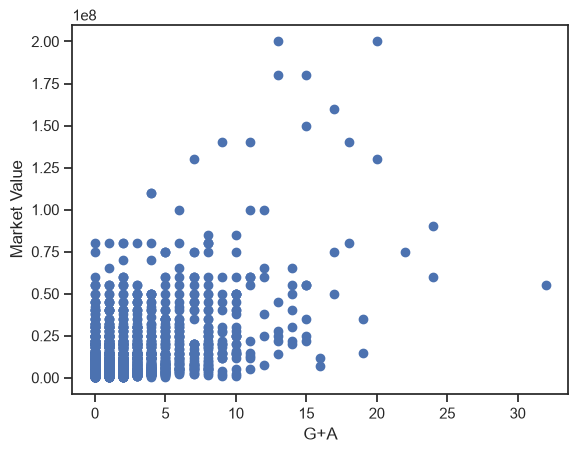

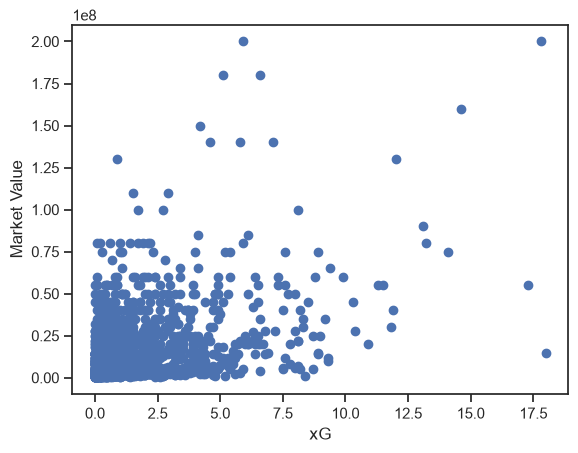

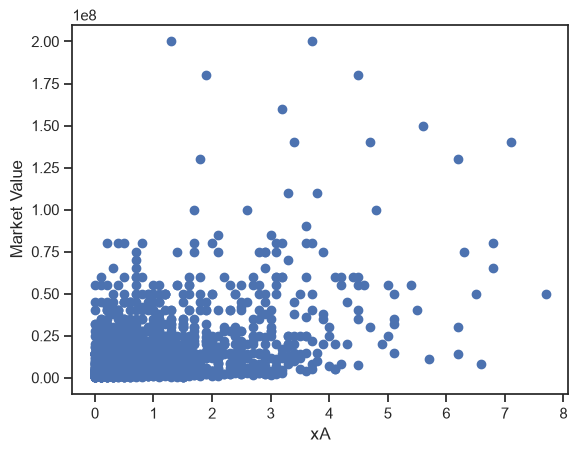

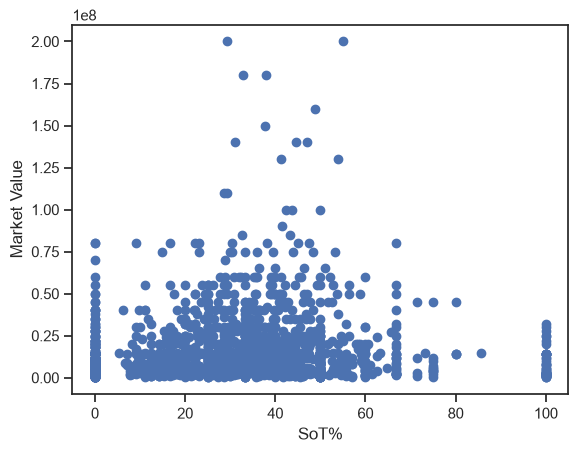

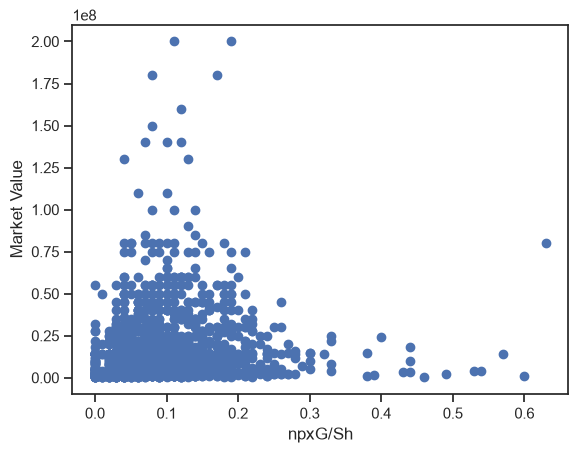

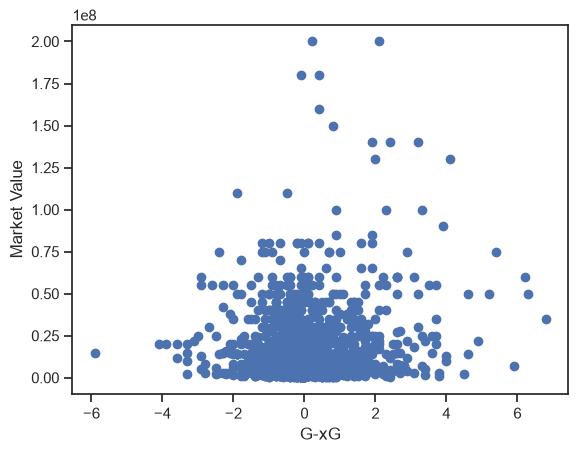

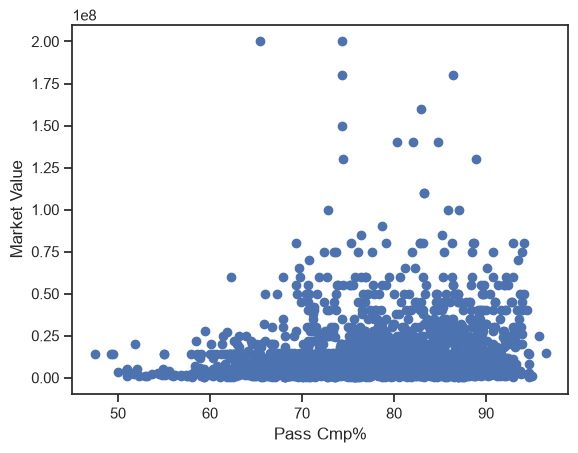

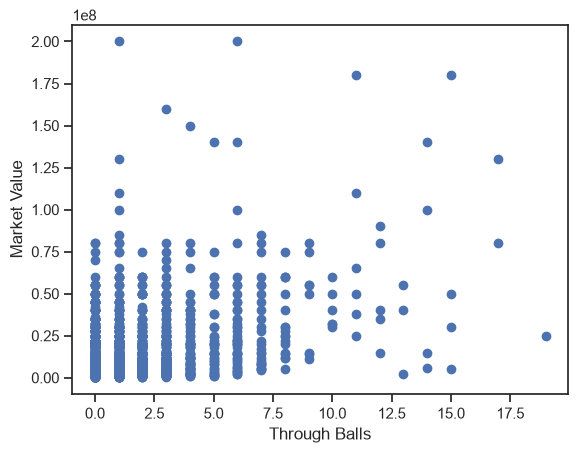

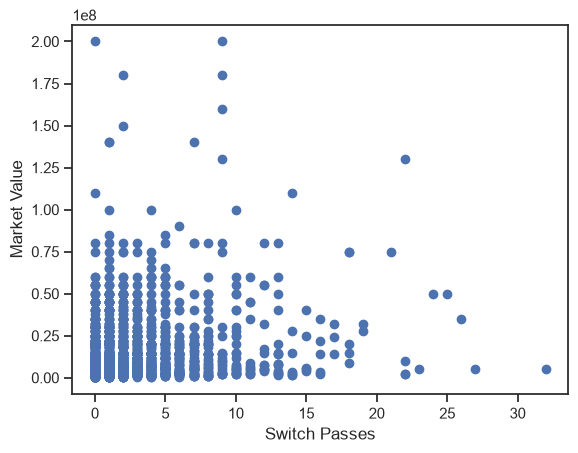

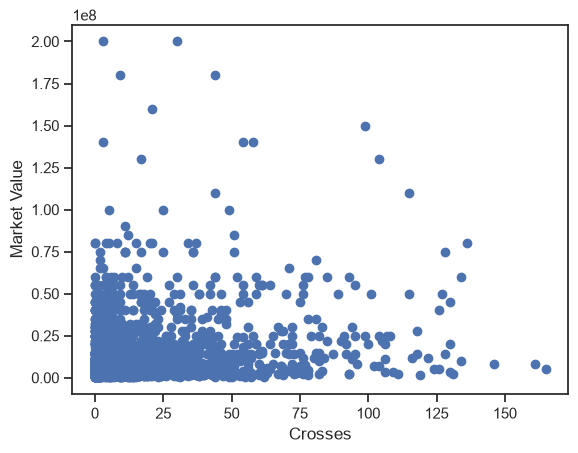

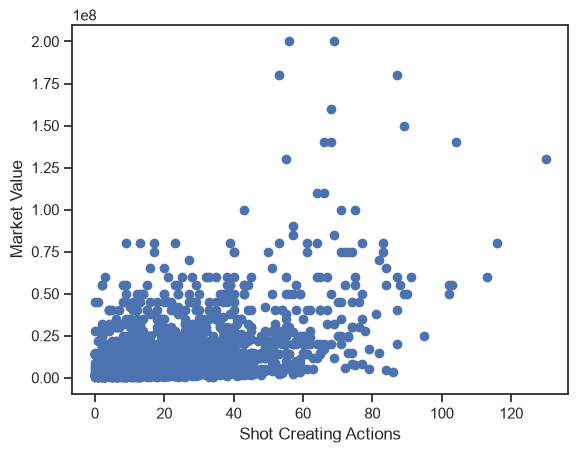

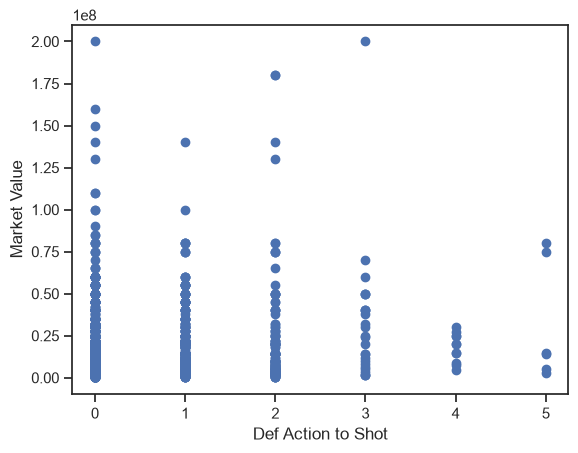

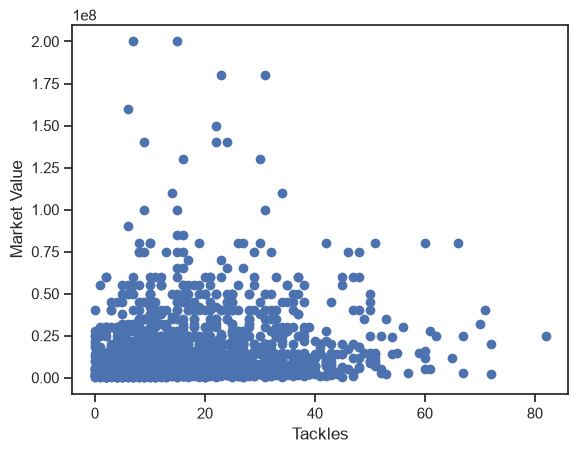

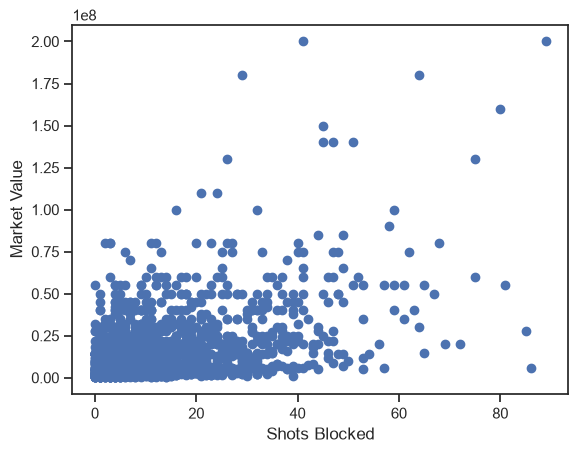

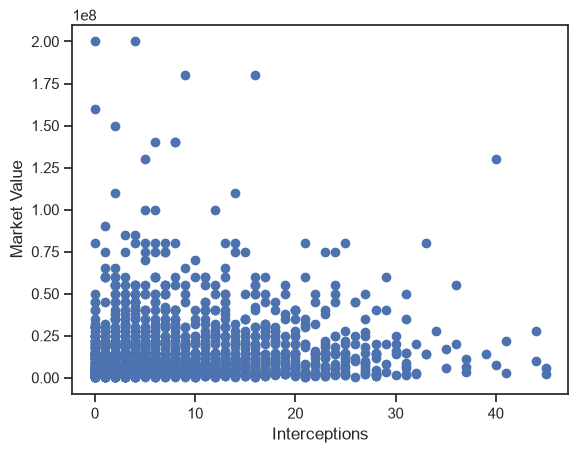

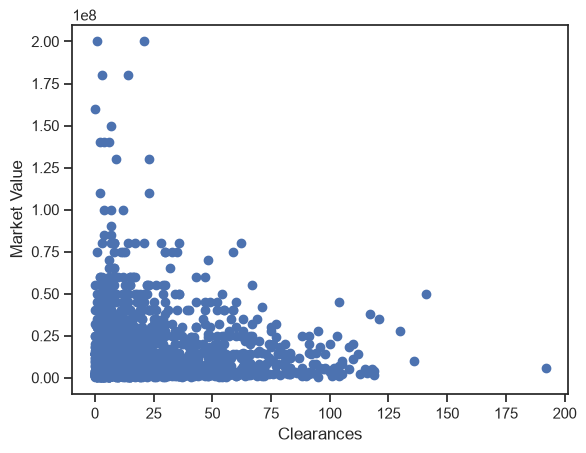

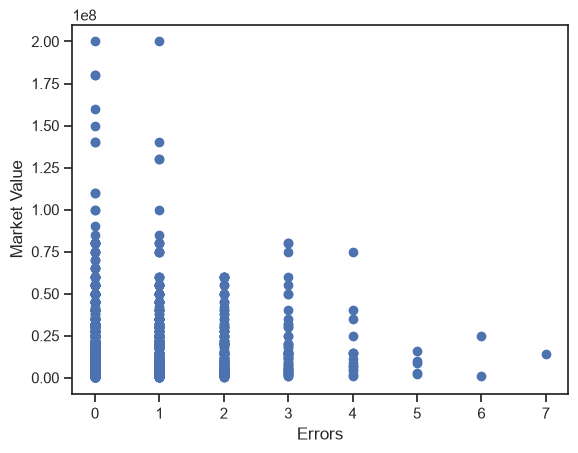

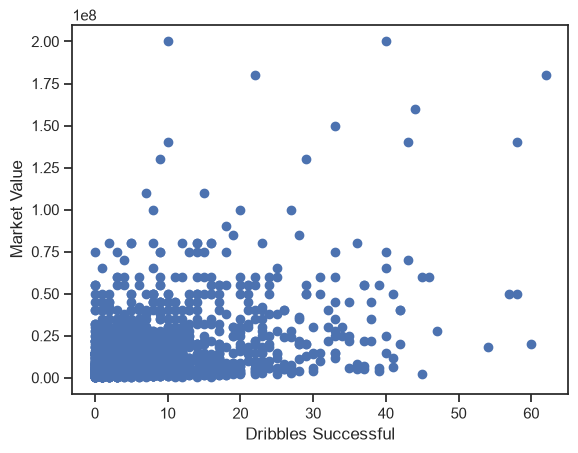

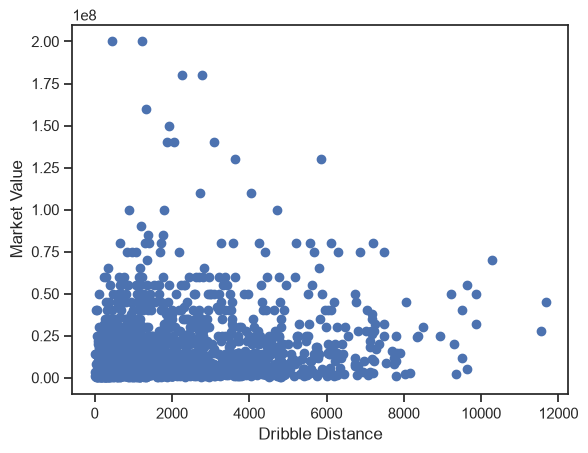

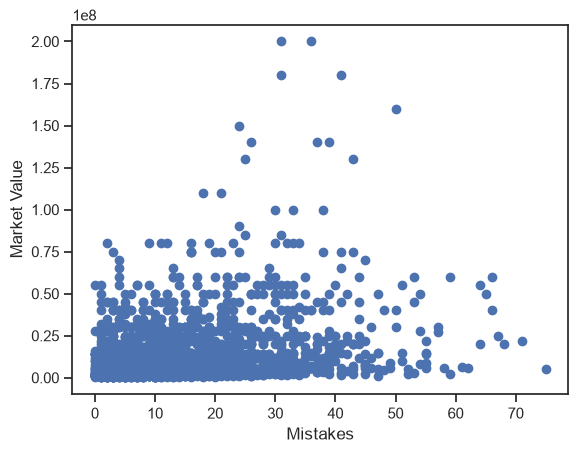

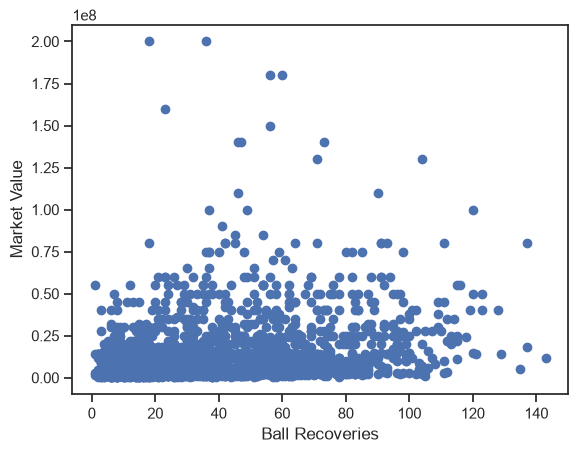

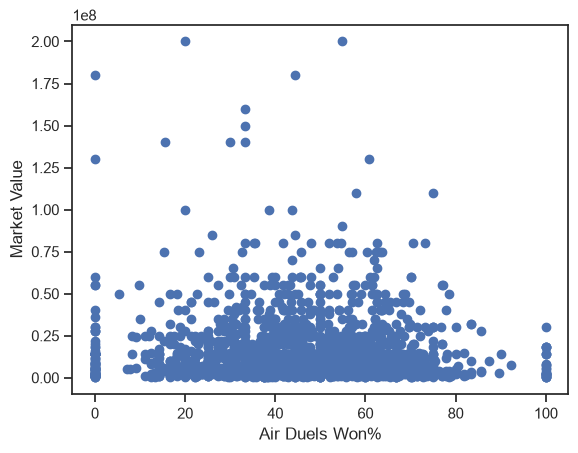

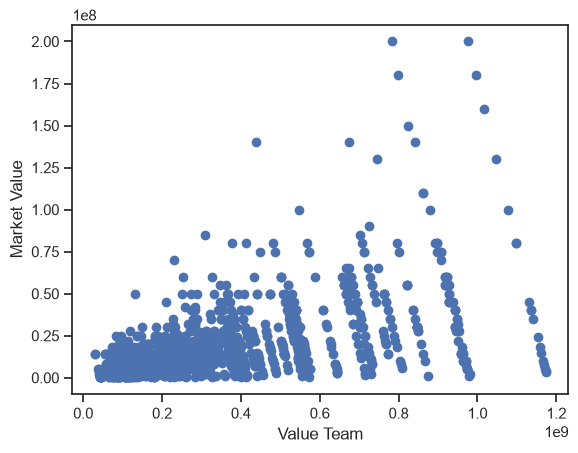

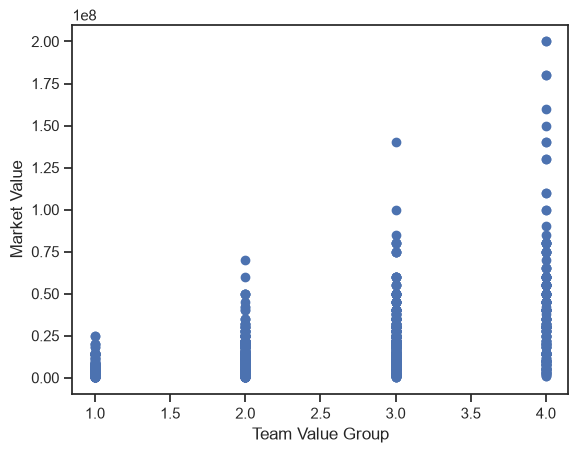

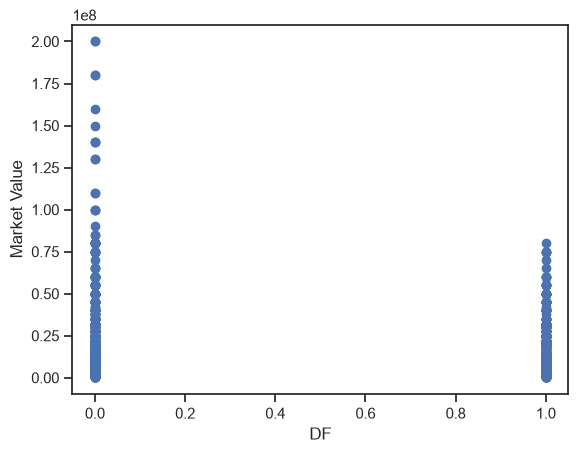

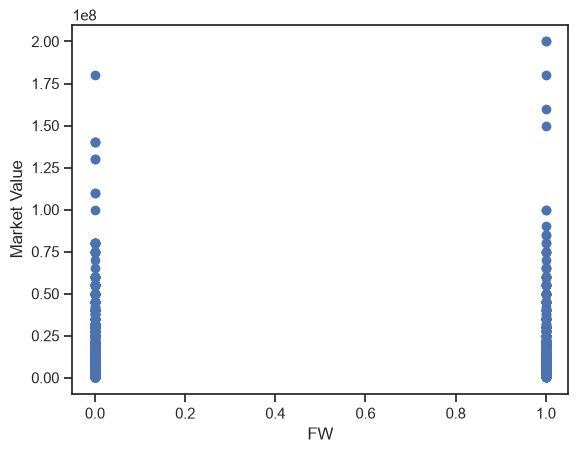

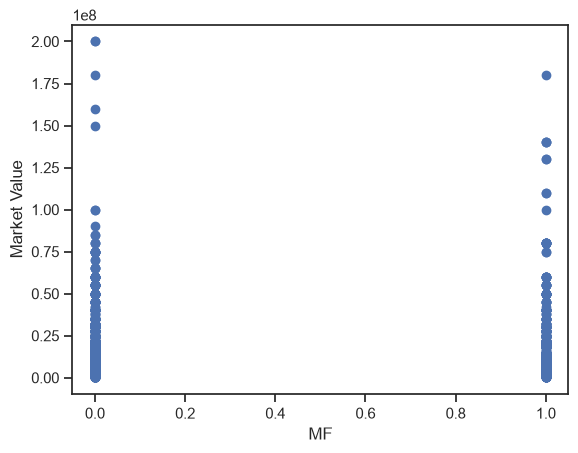

In [38]:
# variables vs market value

for col in X.columns: 
    plt.figure()
    plt.scatter(X[col], y)
    plt.ylabel('Market Value')
    plt.xlabel(col)
    
    plt.show()

In [39]:
# Libraries for modeling

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, RobustScaler

from sklearn.linear_model import LinearRegression

In [40]:
df1 = data.copy()
mask = data['Values'] > 0   # values greater than 0
df1['Values'] = np.where(mask, np.log(data.loc[mask, 'Values']), np.nan) 

Storing the log values instead of values directly because some of the superstars have extremely high values.

In [41]:
# Rename 'Values' column for clarity
df1 = df1.rename(columns={'Values': 'Log Market Value'})

In [42]:
# one-Hot Encoding for position
df1['Is_Defender'] = (df1['DF'] > 0).astype(int)
df1['Is_Forward'] = (df1['FW'] > 0).astype(int)
df1['Is_Midfielder'] = (df1['MF'] > 0).astype(int)


# feature engineering
df1['Goals_per_MP'] = df1['Goals'] / df1['MP']
df1['Assists_per_MP'] = df1['Ast'] / df1['MP']
df1['Shot_Creating_Actions_per_MP'] = df1['Shot Creating Actions'] / df1['MP']
df1['Through_Balls_per_MP'] = df1['Through Balls'] / df1['MP']
df1['Dribbles_Successful_per_MP'] = df1['Dribbles Successful'] / df1['MP']
df1['Offensive_Index'] = df1['Goals'] + df1['Ast'] + 0.5 * df1['Shot Creating Actions']

In [43]:
# list of features
features = [
    'Min',
    'Goals',
    'Ast',
    'xA',
    'xG',
    'G+A',
    'Through Balls',
    'Dribbles Successful',
    'Ball Recoveries',
    'Age',
    'Shots Blocked',
    'Value Team',   
    'Shot Creating Actions',
    'Goals_per_MP',
    'Assists_per_MP',
    'Shot_Creating_Actions_per_MP',
    'Through_Balls_per_MP',
    'Dribbles_Successful_per_MP',
    'Offensive_Index'
    # 'Matches',
    # 'MP'
    ]

In [44]:
# drop the not needed columns
columns_to_drop = [
    'Matches', 'MP',
    'SoT%', 'Dribble Distance','npxG/Sh','Crosses','Tackles','Interceptions','Dribble Distance','Air Duels Won%',
    'Pass Cmp%', 'Switch Passes', 'Def Action to Shot', 
    'Clearances', 'Errors', 'DF', 'FW', 'MF', 'Values', 'Crosses'
]

df1.drop([col for col in columns_to_drop if col in df1.columns], axis=1, errors='ignore', inplace=True)

In [45]:
features = [col for col in features if col in df1.columns]

X = df1[features]
y = df1['Log Market Value']

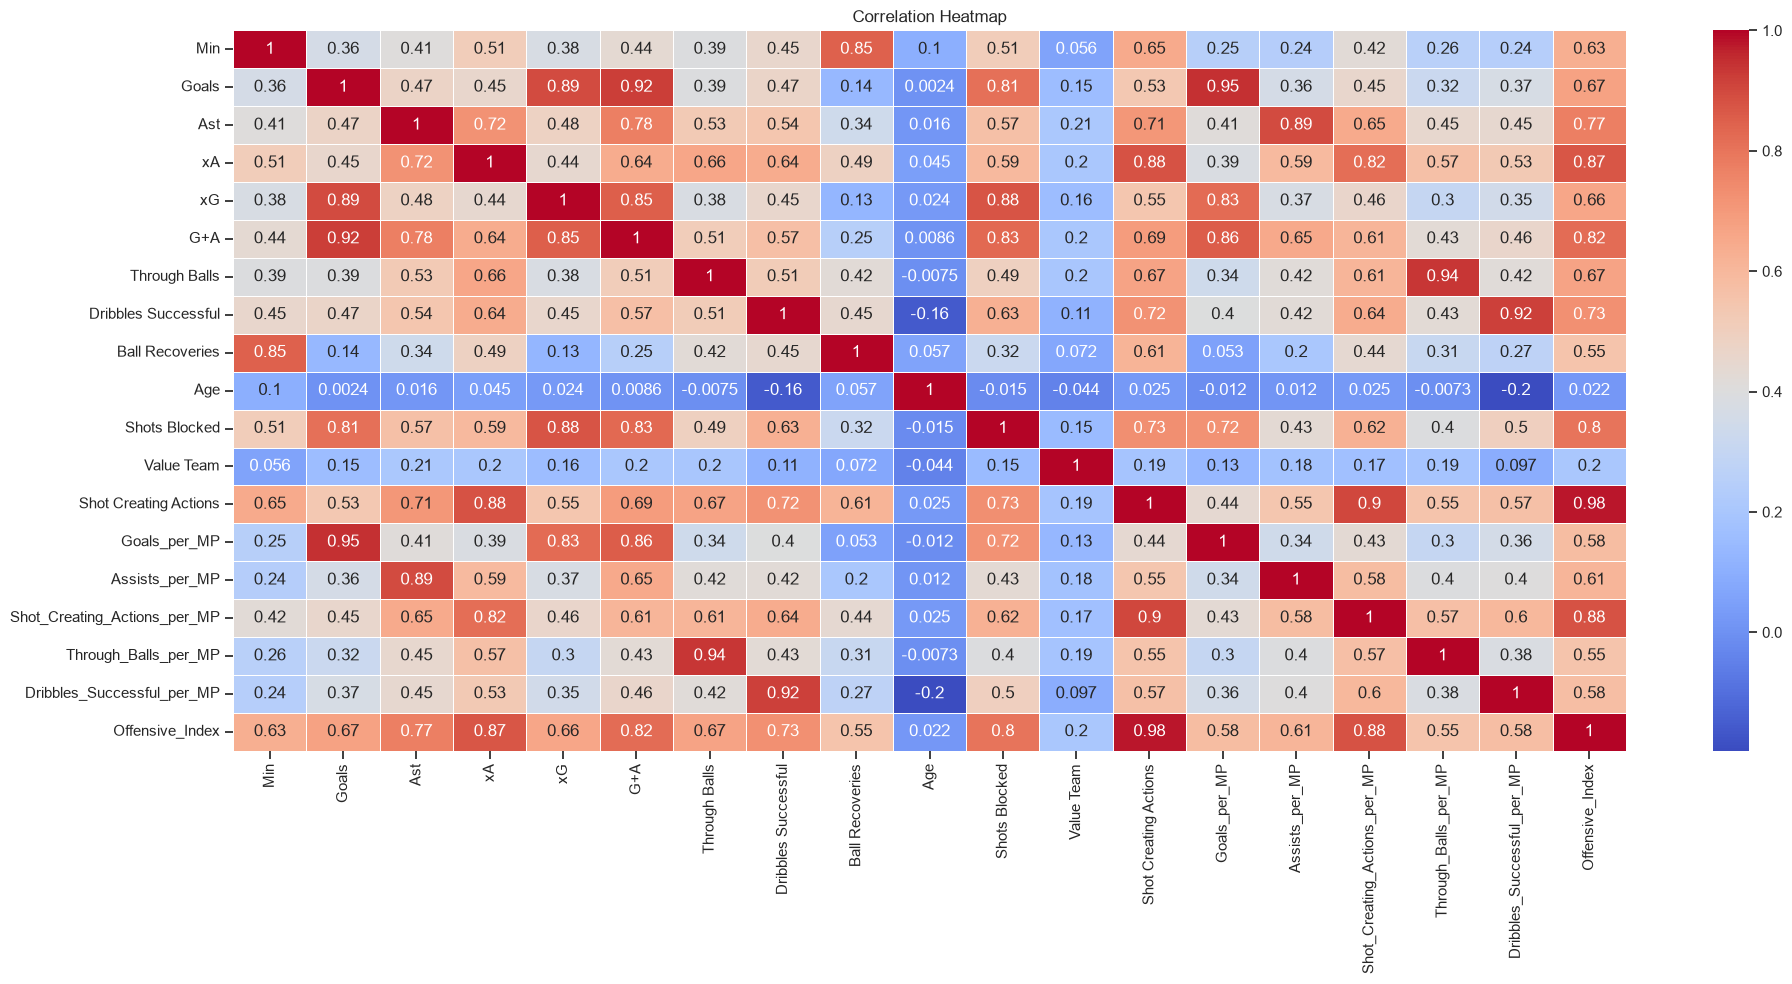

In [46]:
# all features after feature engineering in heatmap

plt.figure(figsize=(20, 10))
sns.heatmap(X.corr(), annot=True, cmap="coolwarm", linewidths=.5)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

In [47]:
# Split the data into training, validation, and test sets

# train - training
# val - validation
# test - testing

X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.25, random_state=42)

In [48]:
# numerical and categorical features

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = ['Is_Defender', 'Is_Forward', 'Is_Midfielder']  

In [49]:

# checking for missing values - just in case

print(X.isnull().sum().sort_values(ascending=False).head(15))
print("Missing target values:", y.isnull().sum())

Min                      0
Goals                    0
Ast                      0
xA                       0
xG                       0
G+A                      0
Through Balls            0
Dribbles Successful      0
Ball Recoveries          0
Age                      0
Shots Blocked            0
Value Team               0
Shot Creating Actions    0
Goals_per_MP             0
Assists_per_MP           0
dtype: int64
Missing target values: 0


### Multiple Linear Regression

In [50]:
# Training the model
lr_model = LinearRegression();
lr_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](19,)","[0.,0.,0.,...,0.,0.,0.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](19,)","['Min','Goals','Ast',...,'Through_Balls_per_MP', 'Dribbles_Successful_per_MP','Offensive_Index']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,14.3
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,19
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [51]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
y_pred = lr_model.predict(X_val)

# predicting on validation data
print("MAE:", mean_absolute_error(y_val, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_val, y_pred)))
print("R²:", r2_score(y_val, y_pred))

MAE: 0.740377101903258
RMSE: 0.9127486049975349
R²: 0.45487489737622033


In [52]:
y_train_pred = lr_model.predict(X_train)

print("Training R²:", r2_score(y_train, y_train_pred))
print("Validation R²:", r2_score(y_val, y_pred))

print("Training MAE:", mean_absolute_error(y_train, y_train_pred))
print("Validation MAE:", mean_absolute_error(y_val, y_pred))

Training R²: 0.4437900687846368
Validation R²: 0.45487489737622033
Training MAE: 0.7362349123188738
Validation MAE: 0.740377101903258


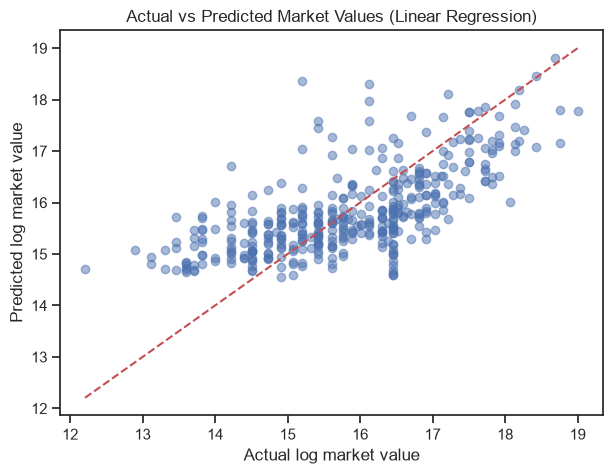

In [53]:
plt.figure(figsize=(7, 5))
plt.scatter(y_val, y_pred, alpha=0.5)

plt.xlabel("Actual log market value")
plt.ylabel("Predicted log market value")
plt.title("Actual vs Predicted Market Values (Linear Regression)")

lower = min(y_val.min(), y_pred.min())
upper = max(y_val.max(), y_pred.max())

plt.plot([lower, upper], [lower, upper], "r--")
plt.show()

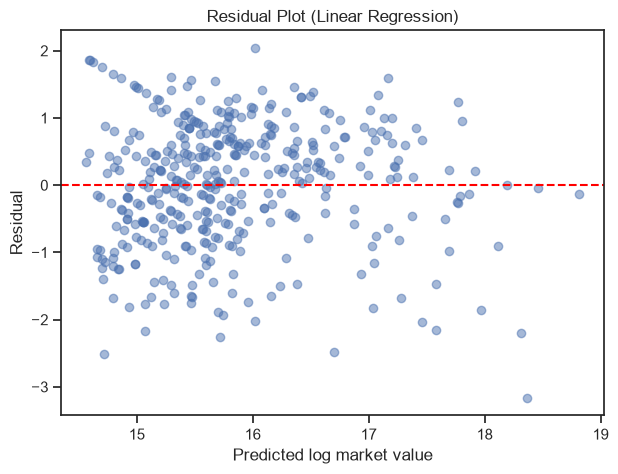

In [54]:
residuals = y_val - y_pred

plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Predicted log market value")
plt.ylabel("Residual")
plt.title("Residual Plot (Linear Regression)")
plt.show()

### Random Forest

In [55]:
from sklearn.ensemble import RandomForestRegressor

# training the data
rf_regressor = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_regressor.fit(X_train, y_train)

y_pred_rf = rf_regressor.predict(X_val)

print("MAE:", mean_absolute_error(y_val, y_pred_rf))
print("RMSE:", np.sqrt(mean_squared_error(y_val, y_pred_rf)))
print("R²:", r2_score(y_val, y_pred_rf))

MAE: 0.5074511994508266
RMSE: 0.6707817447759854
R²: 0.7055874659066792


In [56]:
y_train_pred_rf = rf_regressor.predict(X_train)

print("Training R²:", r2_score(y_train, y_train_pred_rf))
print("Validation R²:", r2_score(y_val, y_pred_rf))

print("Training MAE:", mean_absolute_error(y_train, y_train_pred_rf))
print("Validation MAE:", mean_absolute_error(y_val, y_pred_rf))

Training R²: 0.8840841359060518
Validation R²: 0.7055874659066792
Training MAE: 0.3012479303385007
Validation MAE: 0.5074511994508266


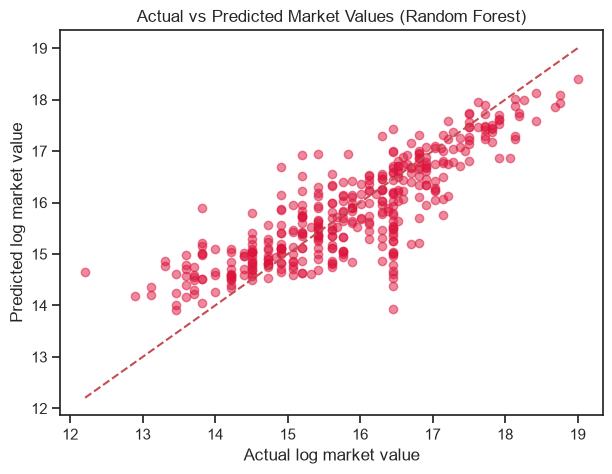

In [57]:
plt.figure(figsize=(7, 5))
plt.scatter(y_val, y_pred_rf, color='crimson' ,alpha=0.5)

plt.xlabel("Actual log market value")
plt.ylabel("Predicted log market value")
plt.title("Actual vs Predicted Market Values (Random Forest)")

lower = min(y_val.min(), y_pred.min())
upper = max(y_val.max(), y_pred.max())

plt.plot([lower, upper], [lower, upper], "r--")
plt.show()

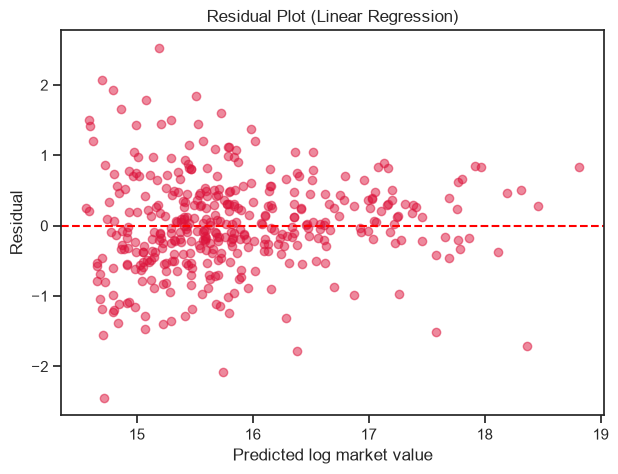

In [58]:
residuals_rf = y_val - y_pred_rf

plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals_rf, color='crimson' ,alpha=0.5)
plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Predicted log market value")
plt.ylabel("Residual")
plt.title("Residual Plot (Linear Regression)")
plt.show()

In [59]:
from xgboost import XGBRegressor

xgb_regressor = XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=2,
    random_state=42,
    n_jobs=-1
)

xgb_regressor.fit(X_train, y_train)

y_pred_xgb = xgb_regressor.predict(X_val)

# print("MAE:", mean_absolute_error(y_val, y_pred_xgb))
# print("RMSE:", np.sqrt(mean_squared_error(y_val, y_pred_xgb)))
# print("R²:", r2_score(y_val, y_pred_xgb))

y_train_pred_xgb = xgb_regressor.predict(X_train)

print("Training R²:", r2_score(y_train, y_train_pred_xgb))
print("Validation R²:", r2_score(y_val, y_pred_xgb))

print("Training MAE:", mean_absolute_error(y_train, y_train_pred_xgb))
print("Validation MAE:", mean_absolute_error(y_val, y_pred_xgb))

Training R²: 0.6920209596399487
Validation R²: 0.6896423868451522
Training MAE: 0.5116705964670194
Validation MAE: 0.5314124123328035


In [60]:
from lightgbm import LGBMRegressor

lgbm_regressor = LGBMRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=-1,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

lgbm_regressor.fit(X_train, y_train)

y_pred_lgbm = lgbm_regressor.predict(X_val)

# print("MAE:", mean_absolute_error(y_val, y_pred_lgbm))
# print("RMSE:", np.sqrt(mean_squared_error(y_val, y_pred_lgbm)))
# print("R²:", r2_score(y_val, y_pred_lgbm))

y_train_pred_lgbm = lgbm_regressor.predict(X_train)

print("Training R²:", r2_score(y_train, y_train_pred_lgbm))
print("Validation R²:", r2_score(y_val, y_pred_lgbm))
print("Training MAE:", mean_absolute_error(y_train, y_train_pred_lgbm))
print("Validation MAE:", mean_absolute_error(y_val, y_pred_lgbm))

Training R²: 0.8873487863322999
Validation R²: 0.7033178481698399
Training MAE: 0.30428679547465315
Validation MAE: 0.5050463591934773


In [61]:
from sklearn.ensemble import GradientBoostingRegressor

gb_regressor = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    min_samples_split=5,
    min_samples_leaf=2,
    loss='squared_error',
    random_state=42
)

gb_regressor.fit(X_train, y_train)

y_pred_gb = gb_regressor.predict(X_val)
y_train_pred_gb = gb_regressor.predict(X_train)

print("Training R²:", r2_score(y_train, y_train_pred_gb))
print("Validation R²:", r2_score(y_val, y_pred_gb))
print("Training MAE:", mean_absolute_error(y_train, y_train_pred_gb))
print("Validation MAE:", mean_absolute_error(y_val, y_pred_gb))
# print("Validation RMSE:", np.sqrt(mean_squared_error(y_val, y_pred_gb)))

Training R²: 0.8090409036107595
Validation R²: 0.7076778569793245
Training MAE: 0.39928186478218997
Validation MAE: 0.5024026522573067


In [62]:
from sklearn.ensemble import ExtraTreesRegressor

et_regressor = ExtraTreesRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

et_regressor.fit(X_train, y_train)

y_pred_et = et_regressor.predict(X_val)
y_train_pred_et = et_regressor.predict(X_train)

print("Training R²:", r2_score(y_train, y_train_pred_et))
print("Validation R²:", r2_score(y_val, y_pred_et))
print("Training MAE:", mean_absolute_error(y_train, y_train_pred_et))
print("Validation MAE:", mean_absolute_error(y_val, y_pred_et))
# print("Validation RMSE:", np.sqrt(mean_squared_error(y_val, y_pred_et)))

Training R²: 0.9509596891106648
Validation R²: 0.6985712685116382
Training MAE: 0.17756984061407136
Validation MAE: 0.5104417033518376


| Model | Training R² | Validation R² | Training MAE | Validation MAE | Validation RMSE |
|---|---:|---:|---:|---:|---:|
| Linear Regression | — | 0.4429 | — | 0.7311 | — |
| Random Forest (Tuned) | 0.8894 | 0.6610 | 0.3005 | 0.5449 | — |
| XGBoost | 0.9147 | 0.6360 | 0.2622 | 0.5484 | 0.7343 |
| LightGBM | 0.8866 | 0.6282 | 0.3053 | 0.5586 | — |
| Gradient Boosting | 0.8086 | 0.6717 | 0.4078 | 0.5253 | — |
| Extra Trees | 0.9545 | 0.6551 | 0.1738 | 0.5407 | — |

Gradient boost has outperformed every model